# EDA Google Maps theo đúng pipeline Foody

Notebook tham chiếu: `eda._present.ipynb`. Dữ liệu: `../data/raw/ggmap/gmap.json`.

**Câu hỏi:** n-gram 1–3 token nào liên hệ với nhóm điểm thấp và giữ được liên hệ khi chia theo nội dung nhiều lần?

Giữ thứ tự 8 phần Foody; kiểm tra mức thiếu của 6 trường khóa ban đầu trước khi chọn 4 trường lọc trùng: **(1)** chất lượng dữ liệu, **(2)** audit 6 trường và lọc trùng 4 khóa, **(3)** khối lượng văn bản, **(4)** phân phối điểm/độ dài và nội dung lặp, **(5)** đọc mẫu, **(6)** working, **(7)** chia theo text, **(8)** support/lift và ổn định.

## Quy ước ánh xạ trước EDA

| Trường Foody dùng | Trường Maps tương đương | Cách dùng |
|---|---|---|
| `review_id` | `review_id` | Chỉ truy vết/hiển thị, không làm khóa lọc trùng |
| `source_platform` | `source` | Nguồn của review |
| `shop_id` | `restaurant_id` | Định danh địa điểm, không dùng tên quán thay thế |
| `comment_datetime` | `published_at` | Giữ thiếu nếu không có ngày chính xác |
| `rating` | `rating` | Maps 1–5 nhân 2 thành thang 0–10 |
| `comment_text` | `text_raw` | Văn bản gốc, sau đó chuẩn hóa đúng code Foody |

Chỉ 6 trường tương đương trên đi vào `eda`. Các cột `rating_num`, `text_norm`, `n_tokens`, `n_chars`, `is_low` là đặc trưng dẫn xuất giống Foody. Không dùng trường cờ/nhãn/split hoặc thông tin địa lý riêng của Maps để quyết định mẫu, lọc trùng, chọn keyword hay kiểm chứng. Không lấy output của `gg_map.ipynb` làm kết quả.

**Hai hệ quả cần phân biệt:**
- Quy đổi thang điểm là bước ánh xạ đơn vị, không học hay thay đổi cảm xúc. Ngưỡng `0 < rating ≤5` của Foody tương ứng Maps **1–2 sao**. Ba sao chuyển thành 6 điểm, thuộc nhóm còn lại. Đây là tương đương số học, chưa chứng minh tương đương tâm lý người chấm.
- Trước khi lọc trùng, audit cả 6 trường: `source_platform`, `shop_id`, `comment_datetime`, `device`, `rating`, `comment_text`. Cột không có trong `eda` được báo rõ, tính thiếu 100%; không tạo dữ liệu giả để lấp khóa.

**Điều chỉnh theo kết quả audit và yêu cầu:** bỏ `comment_datetime` và `device` khỏi khóa. Bốn trường dùng để lọc là `source_platform`, `shop_id`, `rating`, `comment_text`; rating và text dùng bản chuẩn hóa `rating_num`, `text_norm`. Chỉ loại dòng đủ 4 khóa và trùng cả 4 giá trị, giữ dòng đầu tiên. `review_id` chỉ dùng truy vết. Hai review do hai người khác nhau viết vẫn có thể bị gộp nếu cùng quán, điểm và nội dung; vì vậy đây là lọc trùng theo thuộc tính, chưa chứng minh bản ghi bị cào lặp.

**Trạng thái bản chỉnh sửa:** đã xóa output cũ từ phase 2 trở đi vì đổi khóa sẽ tác động các thống kê phía sau. Cần Restart Kernel & Run All khi có dữ liệu gốc. Phần 9 còn cần notebook Foody và dữ liệu của Foody; các nhận xét có số liệu sau lọc được sinh lại từ biến của lần chạy mới.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


## Đọc dữ liệu và đưa về đúng schema Foody

Chỉ lấy các trường tương đương đã liệt kê. Bảng ánh xạ rating giúp kiểm tra rằng ngưỡng ≤5 hoạt động đúng sau đổi thang. `df_raw` lưu bản đầu vào đã ánh xạ trước các bước EDA, không ghi đè JSON gốc.

In [2]:
from pathlib import Path
import json
from IPython.display import Markdown
%matplotlib inline

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data/raw/ggmap/gmap.json').is_file())
DATA_PATH = ROOT / 'data/raw/ggmap/gmap.json'
SOURCE_TO_FOODY = {
    'review_id': 'review_id',
    'source': 'source_platform',
    'restaurant_id': 'shop_id',
    'published_at': 'comment_datetime',
    'rating': 'rating',
    'text_raw': 'comment_text',
}
with DATA_PATH.open(encoding='utf-8') as handle:
    raw_records = json.load(handle)
if not isinstance(raw_records, list) or not raw_records:
    raise ValueError('Nguồn phải là danh sách review không rỗng.')
absent = set(SOURCE_TO_FOODY) - set().union(*(row.keys() for row in raw_records))
if absent:
    raise ValueError(f'Không tìm thấy trường tương đương: {sorted(absent)}')
eda = pd.DataFrame.from_records(
    [{target: row.get(source) for source, target in SOURCE_TO_FOODY.items()}
     for row in raw_records],
    columns=list(SOURCE_TO_FOODY.values()),
)
del raw_records
# Giữ ID là chuỗi, không suy luận ID thành số.
for col in ['review_id', 'source_platform', 'shop_id']:
    eda[col] = eda[col].astype('string')
original_rating = pd.to_numeric(eda['rating'], errors='coerce')
rating_mapping = original_rating.value_counts(dropna=False).rename_axis('Sao Maps').reset_index(name='Số review')
rating_mapping['Điểm tương đương Foody'] = rating_mapping['Sao Maps'] * 2
rating_mapping['Nhóm thấp sau đổi thang'] = rating_mapping['Điểm tương đương Foody'].between(0, 5)
display(rating_mapping.sort_values('Sao Maps', na_position='last'))
# Giá trị lỗi không chuyển được thành số được giữ nguyên để phase 1 audit.
eda['rating'] = eda['rating'].map(lambda v: v * 2 if isinstance(v, (int, float)) else v)
df_raw = eda.copy(deep=True)
assert list(eda.columns) == list(SOURCE_TO_FOODY.values())
eda.info()

,Sao Maps,Số review,Điểm tương đương Foody,Nhóm thấp sau đổi thang
2,1.0,14784,2.0,True
4,2.0,4777,4.0,True
3,3.0,11096,6.0,False
1,4.0,26042,8.0,False
0,5.0,89856,10.0,False
5,NaN,1010,NaN,False


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 147565 entries, 0 to 147564
Data columns (total 6 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   review_id         147565 non-null  string 
 1   source_platform   147565 non-null  string 
 2   shop_id           147565 non-null  string 
 3   comment_datetime  0 non-null       object 
 4   rating            146555 non-null  float64
 5   comment_text      147565 non-null  object 
dtypes: float64(1), object(2), string(3)
memory usage: 6.8+ MB


## 1. Kiểm tra chất lượng dữ liệu

**Làm gì:** giữ nguyên code Foody để chuẩn hóa NFC, chữ thường, khoảng trắng; audit comment thiếu/rỗng, rating thiếu/không đọc được/ngoài 0–10, rating 0 và text lặp.

**Vì sao:** chỉ review có văn bản và điểm hợp lệ mới tạo được bằng chứng liên hệ text–rating. Đếm text lặp ở đây là khảo sát, chưa xóa theo text.

**Đọc kết quả:** các điều kiện thiếu có thể chồng lấn, không cộng các dòng audit thành tổng bị loại.

In [3]:
required_columns = {"rating", "comment_text"}
missing_columns = required_columns - set(eda.columns)

if missing_columns:
    raise ValueError(f"Thiếu các cột: {sorted(missing_columns)}")

# Giữ toàn bộ cột trong eda để còn khảo sát khóa lọc trùng.
eda["rating_num"] = pd.to_numeric(eda["rating"], errors="coerce")

# Giữ comment gốc; tạo bản chuẩn hóa riêng để thống kê
eda["text_norm"] = (
    eda["comment_text"]
    .astype("string")
    .fillna("")
    .str.normalize("NFC")
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

text_missing = eda["comment_text"].isna()
text_empty = eda["text_norm"].eq("")
rating_missing = eda["rating"].isna()
rating_unreadable = (
    eda["rating"].notna() & eda["rating_num"].isna()
)
rating_outside = (
    eda["rating_num"].notna()
    & ~eda["rating_num"].between(0, 10)
)

valid = (
    ~text_empty
    & eda["rating_num"].between(0, 10)
)

audit = pd.Series({
    "Tổng số dòng": len(eda),
    "Comment thiếu": int(text_missing.sum()),
    "Comment rỗng, gồm cả thiếu": int(text_empty.sum()),
    "Rating thiếu": int(rating_missing.sum()),
    "Rating không chuyển được thành số": int(rating_unreadable.sum()),
    "Rating ngoài khoảng 0–10": int(rating_outside.sum()),
    "Dòng có rating = 0": int(eda["rating_num"].eq(0).sum()),
    "Dòng đủ comment và rating hợp lệ": int(valid.sum()),
}, name="Số lượng")

display(audit.to_frame())

# Tập hợp lệ cho audit; chưa lọc comment trùng và vẫn giữ rating 0.
corpus = eda.loc[valid].copy()

if corpus.empty:
    raise ValueError("Không có review đáp ứng điều kiện đầu vào.")

duplicate_text = corpus["text_norm"].duplicated(keep=False)

duplicate_summary = pd.Series({
    "Số nội dung khác nhau": corpus["text_norm"].nunique(),
    "Số dòng thuộc nhóm nội dung lặp": int(duplicate_text.sum()),
    "Số dòng dư nếu chỉ giữ 1 dòng mỗi nội dung":
        int(corpus["text_norm"].duplicated().sum()),
}, name="Số lượng")

display(duplicate_summary.to_frame())

,Số lượng
Tổng số dòng,147565
Comment thiếu,0
"Comment rỗng, gồm cả thiếu",15534
Rating thiếu,1010
Rating không chuyển được thành số,0
Rating ngoài khoảng 0–10,0
Dòng có rating = 0,0
Dòng đủ comment và rating hợp lệ,131021


,Số lượng
Số nội dung khác nhau,124754
Số dòng thuộc nhóm nội dung lặp,7409
Số dòng dư nếu chỉ giữ 1 dòng mỗi nội dung,6267


### Khảo sát rating 0 như Foody

Đọc tối đa 5 review rating 0 rồi đo tỷ trọng trong nhóm ≤5. Nếu không có, bảng mẫu rỗng là kết quả hợp lệ. Không mang nhận định “rating 0 tích cực” của Foody sang Maps khi chưa có dữ liệu.

In [4]:
with pd.option_context("display.max_colwidth", None):
    display(
        eda.loc[eda["rating_num"].eq(0), ["rating", "comment_text"]].head(5)
    )

,rating,comment_text


In [5]:
low_reviews = eda.loc[eda["rating_num"].between(0, 5)]

n_low = len(low_reviews)
n_zero = int(low_reviews["rating_num"].eq(0).sum())
percent_zero = n_zero / n_low * 100 if n_low else 0

print(f"Tổng review điểm thấp (0 ≤ rating ≤ 5): {n_low:,}")
print(f"Số review rating = 0: {n_zero:,}")
print(f"Tỷ lệ rating = 0 trong nhóm điểm thấp: {percent_zero:.4f}%")

Tổng review điểm thấp (0 ≤ rating ≤ 5): 19,561
Số review rating = 0: 0
Tỷ lệ rating = 0 trong nhóm điểm thấp: 0.0000%


### Kết quả phase 1

- Nguồn có **147.565 review**. Comment thiếu dạng null: **0**, nhưng có **15.534 comment rỗng sau chuẩn hóa** (10.53%). Vì vậy nhìn riêng `notna()` sẽ bỏ sót vấn đề văn bản rỗng.
- Có **1.010 review thiếu điểm**. Rating không đọc được: 0, ngoài miền sau đổi thang: 0. Có **131.021 review** đồng thời có text và điểm hợp lệ.
- Rating 0: **0**. Maps hiện tại không cung cấp bằng chứng để lặp lại nhận định rating 0 của Foody. Vẫn giữ đúng bước khảo sát và quy tắc loại rating 0 ở phase 6.

Tập hợp lệ phục vụ phân tích văn bản có thể khác thành phần rating của toàn nguồn. Kết luận keyword phía sau chỉ áp dụng cho tập đã lọc, không cho các review không có văn bản.

## 2. Lọc comment trùng

### 2.1. Kiểm tra tỷ lệ thiếu của 6 trường khóa ban đầu

Audit **trước khi chọn khóa**: `source_platform`, `shop_id`, `comment_datetime`, `device`, `rating`, `comment_text`. Mỗi trường có số dòng thiếu, tỷ lệ thiếu và trạng thái có cột trong `eda`. Cột không tồn tại được tính thiếu toàn bộ; không thêm `device` giả vào đầu vào.

Dùng `rating_num` và `text_norm` cho rating và nội dung để khớp giá trị thực sự dùng trong bước lọc. Chuỗi rỗng, null và placeholder đều là thiếu. Bảng thứ hai đối chiếu số review đủ bộ 6 khóa với bộ 4 khóa đề xuất; một trường thiếu toàn bộ khiến bộ 6 không xét được dòng nào.

In [6]:
# Audit cả 6 trường trước khi quyết định dùng 4 trường để lọc trùng.
features = [
    "source_platform", "shop_id", "comment_datetime",
    "device", "rating", "comment_text",
]
field_mapping = {field: field for field in features}
field_mapping.update(rating="rating_num", comment_text="text_norm")
missing_values = {"", "unknown", "none", "null", "nan", "nat", "<na>", "n/a"}
audit_keys = pd.DataFrame(index=eda.index)
summary = []

for field, column in field_mapping.items():
    exists = column in eda.columns
    if not exists:
        values = pd.Series(pd.NA, index=eda.index, dtype="string")
    elif field == "rating":
        values = pd.to_numeric(eda[column], errors="coerce")
    else:
        values = eda[column].astype("string").str.normalize("NFC").str.strip()
        values = values.mask(values.str.lower().isin(missing_values))
    audit_keys[field] = values
    n_missing = int(values.isna().sum())
    summary.append({
        "Trường": field,
        "Cột kiểm tra": column,
        "Có cột trong eda": exists,
        "Số review thiếu": n_missing,
        "Tỷ lệ thiếu (%)": 100 * n_missing / len(eda) if len(eda) else np.nan,
    })

print(f"Phạm vi audit: toàn bộ {len(eda):,} review trước lọc trùng, ở mọi mức rating.")
missing_report = pd.DataFrame(summary)
display(missing_report.round({"Tỷ lệ thiếu (%)": 4}))

dedup_features = ["source_platform", "shop_id", "rating", "comment_text"]
availability_report = pd.DataFrame([
    {
        "Bộ khóa": label,
        "Review đủ khóa": int(audit_keys[fields].notna().all(axis=1).sum()),
        "Tỷ lệ đủ khóa (%)": 100 * audit_keys[fields].notna().all(axis=1).mean(),
    }
    for label, fields in [
        ("6 trường ban đầu", features),
        ("4 trường được chọn", dedup_features),
    ]
])
display(availability_report.round({"Tỷ lệ đủ khóa (%)": 4}))

# Diễn giải bằng kết quả audit hiện tại, không đặt cứng số liệu từ lần chạy cũ.
for field in ["comment_datetime", "device"]:
    row = missing_report.loc[missing_report["Trường"].eq(field)].iloc[0]
    status = "có cột" if row["Có cột trong eda"] else "không có cột trong eda"
    print(f"{field}: {status}; thiếu {row['Số review thiếu']:,}/{len(eda):,} review "
          f"({row['Tỷ lệ thiếu (%)']:.2f}%).")
if len(eda) and audit_keys[["comment_datetime", "device"]].isna().all().all():
    print("Cả ngày đăng và device đều thiếu toàn bộ: bộ 6 khóa không phát hiện được trùng.")
else:
    print("Mức thiếu đã được hiển thị ở trên; chỉ phần đủ cả 6 khóa mới xét được theo bộ cũ.")
print("Theo yêu cầu, bước tiếp theo dùng 4 khóa: nguồn, quán, rating và nội dung chuẩn hóa. "
      "Dòng thiếu bất kỳ khóa nào trong 4 khóa vẫn được giữ.")

Phạm vi audit: toàn bộ 147,565 review trước lọc trùng, ở mọi mức rating.


,Trường,Cột kiểm tra,Có cột trong eda,Số review thiếu,Tỷ lệ thiếu (%)
0,source_platform,source_platform,True,0,0.0000
1,shop_id,shop_id,True,0,0.0000
2,comment_datetime,comment_datetime,True,147565,100.0000
3,device,device,False,147565,100.0000
4,rating,rating_num,True,1010,0.6844
5,comment_text,text_norm,True,15534,10.5269


,Bộ khóa,Review đủ khóa,Tỷ lệ đủ khóa (%)
0,6 trường ban đầu,0,0.0000
1,4 trường được chọn,131021,88.7887


comment_datetime: có cột; thiếu 147,565/147,565 review (100.00%).
device: không có cột trong eda; thiếu 147,565/147,565 review (100.00%).
Cả ngày đăng và device đều thiếu toàn bộ: bộ 6 khóa không phát hiện được trùng.
Theo yêu cầu, bước tiếp theo dùng 4 khóa: nguồn, quán, rating và nội dung chuẩn hóa. Dòng thiếu bất kỳ khóa nào trong 4 khóa vẫn được giữ.


### 2.2. Chọn 4 trường và thực hiện lọc trùng

Sau khi xem bảng tỷ lệ thiếu và số review đủ khóa ở mục 2.1, bỏ **`comment_datetime` và `device`** khỏi điều kiện lọc theo yêu cầu. Không dùng ID review hay trường riêng của Maps để thay thế.

Khóa gồm **`source_platform`, `shop_id`, `rating_num`, `text_norm`**. Hai khóa cuối là bản chuẩn hóa của `rating` và `comment_text`. Chỉ loại dòng **đủ cả 4 khóa và trùng cả 4 giá trị**, giữ dòng đầu tiên. Dòng thiếu một trong 4 khóa vẫn được giữ. Tái sử dụng giá trị đã chuẩn hóa trong audit để việc kiểm tra thiếu và lọc trùng nhất quán.

Quy tắc này có thể gộp review của nhiều người cùng viết câu ngắn như “ngon” ở cùng quán và cùng điểm. Vì vậy báo là **trùng theo 4 thuộc tính**, chưa khẳng định cùng một review gốc. Đây là thay đổi phương pháp so với khóa 6 trường của Foody.

`corpus` được tạo lại từ `eda_clean` và điều kiện hợp lệ phase 1. Mọi phân tích tiếp theo dùng tập đã lọc này. Bảng theo rating không bao quát review thiếu điểm; dòng “Toàn bộ dataset” là mốc bảo toàn số dòng.

In [7]:
# Bộ 4 khóa; dùng đúng các giá trị đã audit ở mục 2.1.
keys = audit_keys[dedup_features].rename(columns={
    "rating": "rating_num", "comment_text": "text_norm",
}).copy()

complete_key = keys.notna().all(axis=1)
duplicate_mask = complete_key & keys.duplicated(keep="first")

eda_clean = eda.loc[~duplicate_mask].copy()
dedup_removed = eda.loc[duplicate_mask].copy()

assert len(eda) == len(eda_clean) + len(dedup_removed)
assert not duplicate_mask.loc[~complete_key].any()

print(f"Tổng review trước lọc: {len(eda):,}")
print(f"Review thiếu khóa, được giữ: {(~complete_key).sum():,}")
print(f"Review trùng bị loại: {len(dedup_removed):,}")
print(f"Tổng review sau lọc: {len(eda_clean):,}")

filter_report = pd.DataFrame([
    {
        "Nhóm": label,
        "Trước lọc": int(mask.sum()),
        "Bị loại": int((mask & duplicate_mask).sum()),
        "Sau lọc": int((mask & ~duplicate_mask).sum()),
    }
    for label, mask in [
        ("Toàn bộ dataset", pd.Series(True, index=eda.index)),
        ("Rating ≤5 (gồm 0)", eda["rating_num"].le(5)),
        ("Rating >5", eda["rating_num"].gt(5)),
    ]
])
display(filter_report)
display(dedup_removed[["review_id"] + dedup_features].head(5))


# Dùng lại kết quả kiểm tra hợp lệ trước đó, không kiểm tra lại miền rating.
corpus = eda_clean.loc[valid.loc[eda_clean.index]].copy()

Tổng review trước lọc: 147,565
Review thiếu khóa, được giữ: 16,544
Review trùng bị loại: 669
Tổng review sau lọc: 146,896


,Nhóm,Trước lọc,Bị loại,Sau lọc
0,Toàn bộ dataset,147565,669,146896
1,Rating ≤5 (gồm 0),19561,15,19546
2,Rating >5,126994,654,126340


,review_id,source_platform,shop_id,rating,comment_text
5941,gmap:0a17a3a6f7df0c914a51145d82b1b3df,gmap,gmap:fb757e45f39c33f46fc4a26c,10.0,Ngon
8920,gmap:0f0a7d70e85de7c5f89d4ba0291678e2,gmap,gmap:fad1084f254b3337e5b7743d,10.0,Tuyệt vời
9370,gmap:0fcc76cbd04e085428dbd26b39cbe134,gmap,gmap:dd2969dd3bebe37bbcd8362b,10.0,Cafe Ngon
10971,gmap:12a8dc6b0d2ec3e48492a24cfdfa01c0,gmap,gmap:4339ae5b8a0fef3a24a0d81e,10.0,Ngon
12351,gmap:14f661966de6652ec5e9eeb184bff44e,gmap,gmap:748112b6e3c7e490c19d8b6b,10.0,Rất tốt


In [8]:
display(Markdown(
    f"### Kết quả phase 2 — khóa 4 trường\n\n"
    f"Từ **{len(eda):,} review**, có **{int(complete_key.sum()):,} dòng đủ 4 khóa**; "
    f"**{int((~complete_key).sum()):,} dòng thiếu khóa được giữ**. "
    f"Loại **{len(dedup_removed):,} dòng trùng theo 4 thuộc tính**, "
    f"còn **{len(eda_clean):,} dòng** sau dedup và **{len(corpus):,} review hợp lệ** "
    "cho phân tích văn bản.\n\n"
    "Không đồng nhất số dòng bị loại với số bản ghi cào lặp: khóa không chứa người viết "
    "hoặc ngày đăng. Các thống kê phía sau được tính lại từ corpus này."
))

### Kết quả phase 2 — khóa 4 trường

Từ **147,565 review**, có **131,021 dòng đủ 4 khóa**; **16,544 dòng thiếu khóa được giữ**. Loại **669 dòng trùng theo 4 thuộc tính**, còn **146,896 dòng** sau dedup và **130,352 review hợp lệ** cho phân tích văn bản.

Không đồng nhất số dòng bị loại với số bản ghi cào lặp: khóa không chứa người viết hoặc ngày đăng. Các thống kê phía sau được tính lại từ corpus này.

## 3. Đo khối lượng văn bản cần xử lý

Giữ tokenizer regex `(?u)w+`: mỗi đoạn liên tiếp gồm ký tự chữ/số/gạch dưới là một token. Với tiếng Việt đây thường là các âm tiết, chưa phải tách từ ghép có ngữ nghĩa. Emoji/dấu câu riêng lẻ không tạo token theo quy tắc này.

`n_chars` đếm ký tự trong `text_norm`, `n_tokens` đếm token regex. Bảng percentile mô tả review điển hình và đuôi dài; chỉ số lượng review chưa cho biết khối lượng xử lý.

In [9]:
import re
TOKEN_PATTERN = r"(?u)\b\w+\b"
token_regex = re.compile(TOKEN_PATTERN)

if corpus.empty:
    raise ValueError("corpus đang rỗng. Cần chạy bước tạo corpus sau lọc trùng.")

corpus["n_tokens"] = corpus["text_norm"].map(
    lambda text: len(token_regex.findall(text))
)
corpus["n_chars"] = corpus["text_norm"].str.len()

print(f"Phạm vi: {len(corpus):,} review hợp lệ sau lọc trùng, ở mọi mức rating.")

length_summary = (
    corpus[["n_tokens", "n_chars"]]
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
    .rename(columns={
        "n_tokens": "Số token",
        "n_chars": "Số ký tự",
    })
    .round(1)
)

display(length_summary)

n_no_tokens = int(corpus["n_tokens"].eq(0).sum())

print(f"Comment không có token theo regex: {n_no_tokens:,}")
print(f"Tỷ lệ: {n_no_tokens / len(corpus):.2%}")

Phạm vi: 130,352 review hợp lệ sau lọc trùng, ở mọi mức rating.


,Số token,Số ký tự
count,130352.0,130352.0
mean,39.9,176.1
std,53.1,235.5
min,0.0,1.0
50%,23.0,101.0
90%,91.0,400.0
95%,132.0,581.0
99%,262.0,1160.0
max,960.0,4093.0


Comment không có token theo regex: 82
Tỷ lệ: 0.06%


### Ước lượng lượt 1–3 gram

Với L token, số lượt n-gram dài n là `max(L−n+1, 0)`. “Phục vụ quá chậm” tạo 4 unigram, 3 bigram và 2 trigram, tổng 9 lượt. Đây là lượt phải xét trước đếm binary, không phải số keyword khác nhau hay số cột ma trận.

In [10]:
ngram_volume = pd.DataFrame([
    {
        "Loại": f"{n}-gram",
        "Tổng lượt cụm cần xét": int(
            (corpus["n_tokens"] - n + 1).clip(lower=0).sum()
        ),
    }
    for n in [1, 2, 3]
])

display(ngram_volume)

total_occurrences = int(
    ngram_volume["Tổng lượt cụm cần xét"].sum()
)

print(f"Tổng lượt 1–3 gram cần xét: {total_occurrences:,}")

,Loại,Tổng lượt cụm cần xét
0,1-gram,5196465
1,2-gram,5066195
2,3-gram,4937480


Tổng lượt 1–3 gram cần xét: 15,200,140


In [11]:
display(Markdown(
    f"### Kết quả phase 3\n\n"
    f"Trung vị **{corpus['n_tokens'].median():,.1f} token**, "
    f"P95 **{corpus['n_tokens'].quantile(.95):,.1f} token**, "
    f"lớn nhất **{corpus['n_tokens'].max():,} token**. "
    f"Có **{n_no_tokens:,} comment 0 token** dù văn bản không rỗng. "
    f"Tổng khối lượng **{total_occurrences:,} lượt 1–3 gram** trước đếm binary. "
    "Đây là số lượt cần xét, không phải số đặc trưng khác nhau. "
    "Phần chọn keyword vẫn đếm tối đa một lần mỗi review cho mỗi cụm."
))

### Kết quả phase 3

Trung vị **23.0 token**, P95 **132.0 token**, lớn nhất **960 token**. Có **82 comment 0 token** dù văn bản không rỗng. Tổng khối lượng **15,200,140 lượt 1–3 gram** trước đếm binary. Đây là số lượt cần xét, không phải số đặc trưng khác nhau. Phần chọn keyword vẫn đếm tối đa một lần mỗi review cho mỗi cụm.

## 4. Phân phối điểm, độ dài và nội dung lặp

### 4.1. Phân phối rating

Vẽ điểm sau quy đổi về 0–10 đúng code Foody và so nhóm ≤5 với >5. Không chỉ đếm keyword trong nhóm thấp vì hai nhóm có thể rất lệch số lượng. Tỷ lệ nền ở biểu đồ là của `corpus`, chưa phải working sau loại rating 0/0 token.

Tổng review: 130,352
Rating ≤5, gồm cả 0: 18,208 (13.97%)
Rating >5: 112,144 (86.03%)


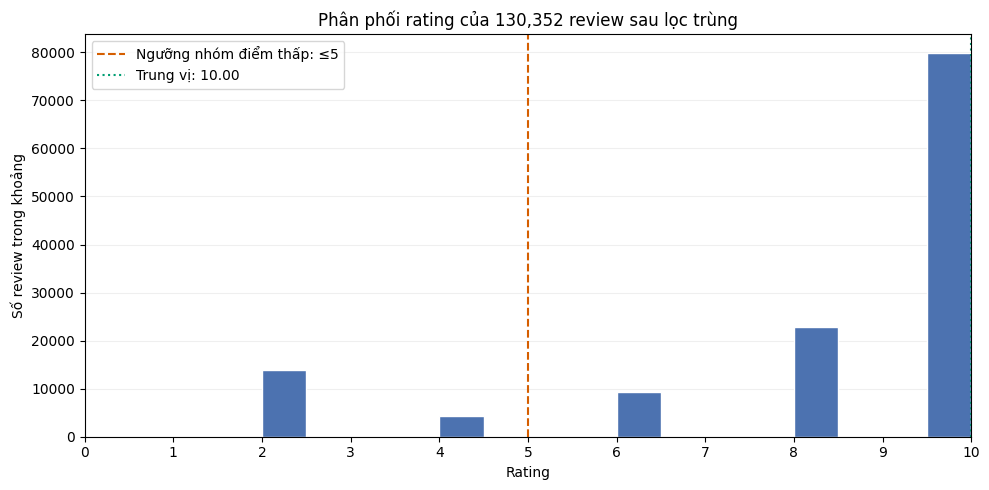

In [12]:
rating = corpus["rating_num"].dropna()

if rating.empty:
    raise ValueError("Không có rating để vẽ.")

n_low = int(rating.le(5).sum())
n_other = int(rating.gt(5).sum())

print(f"Tổng review: {len(rating):,}")
print(f"Rating ≤5, gồm cả 0: {n_low:,} ({n_low / len(rating):.2%})")
print(f"Rating >5: {n_other:,} ({n_other / len(rating):.2%})")

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    rating,
    bins=np.linspace(0, 10, 21),
    color="#4C72B0",
    edgecolor="white",
)

ax.axvline(
    5,
    color="#D55E00",
    linestyle="--",
    label="Ngưỡng nhóm điểm thấp: ≤5",
)

ax.axvline(
    rating.median(),
    color="#009E73",
    linestyle=":",
    label=f"Trung vị: {rating.median():.2f}",
)

ax.set(
    title=f"Phân phối rating của {len(rating):,} review sau lọc trùng",
    xlabel="Rating",
    ylabel="Số review trong khoảng",
    xlim=(0, 10),
    xticks=range(11),
)

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### 4.2. Độ dài trên thang thường

Histogram và các đường trung vị/P95 cho thấy mức tập trung và đuôi review dài. Review dài tạo nhiều cơ hội xuất hiện n-gram, nhưng không tự chứng minh rằng độ dài gây điểm thấp.

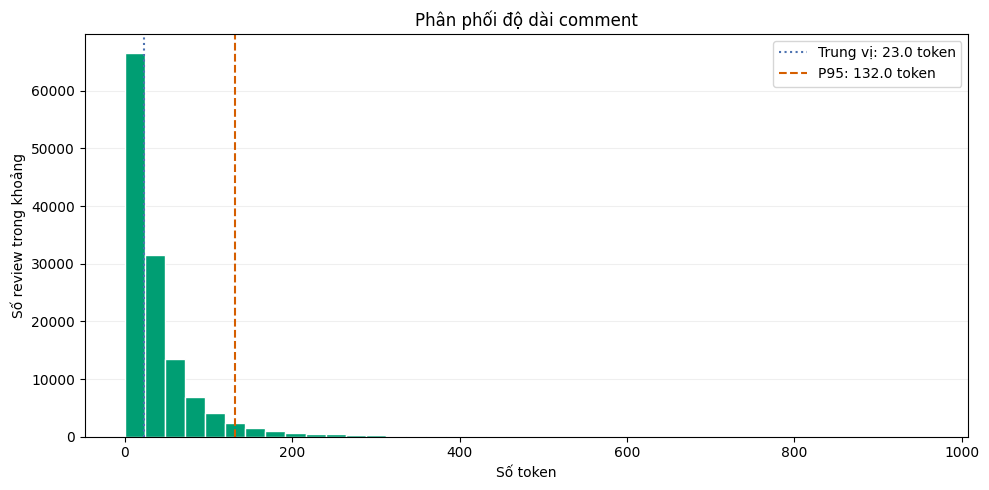

In [13]:
lengths = corpus["n_tokens"].dropna()

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    lengths,
    bins=40,
    color="#009E73",
    edgecolor="white",
)

ax.axvline(
    lengths.median(),
    color="#4C72B0",
    linestyle=":",
    label=f"Trung vị: {lengths.median():.1f} token",
)

ax.axvline(
    lengths.quantile(0.95),
    color="#D55E00",
    linestyle="--",
    label=f"P95: {lengths.quantile(0.95):.1f} token",
)

ax.set(
    title="Phân phối độ dài comment",
    xlabel="Số token",
    ylabel="Số review trong khoảng",
)

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### 4.3. Độ dài trên thang log

Dùng lại code Foody để nhìn rõ đồng thời comment ngắn và rất dài. Chỉ review có token được vẽ trên trục log; số review 0 token được báo riêng. Chiều cao là số review trong từng khoảng, các khoảng log không có cùng độ rộng trên thang thường.

Tổng review được đo: 130,352
Review có token: 130,270
Review 0 token, không vẽ trên trục log: 82


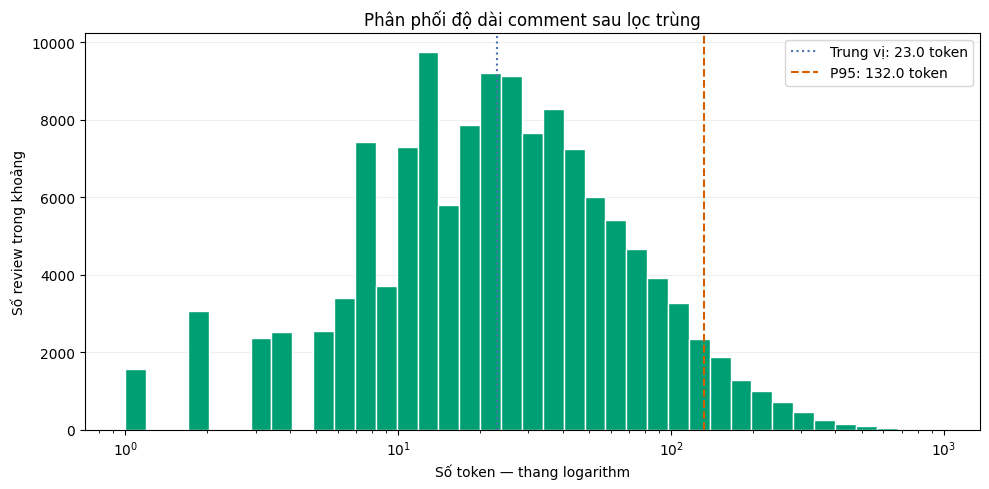

In [14]:
# n_tokens đã được tính ở bước đo khối lượng văn bản.
lengths = corpus["n_tokens"].dropna()
positive_lengths = lengths.loc[lengths.gt(0)]

n_zero = int(lengths.eq(0).sum())

print(f"Tổng review được đo: {len(lengths):,}")
print(f"Review có token: {len(positive_lengths):,}")
print(f"Review 0 token, không vẽ trên trục log: {n_zero:,}")

if positive_lengths.empty:
    raise ValueError("Không có comment có token để vẽ.")

median_length = positive_lengths.median()
p95_length = positive_lengths.quantile(0.95)

# Chia khoảng theo thang logarithm để thể hiện cả phần ngắn và dài.
length_bins = np.geomspace(
    1,
    positive_lengths.max() + 1,
    40,
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    positive_lengths,
    bins=length_bins,
    color="#009E73",
    edgecolor="white",
)

ax.set_xscale("log")

ax.axvline(
    median_length,
    color="#4C72B0",
    linestyle=":",
    label=f"Trung vị: {median_length:.1f} token",
)

ax.axvline(
    p95_length,
    color="#D55E00",
    linestyle="--",
    label=f"P95: {p95_length:.1f} token",
)

ax.set(
    title="Phân phối độ dài comment sau lọc trùng",
    xlabel="Số token — thang logarithm",
    ylabel="Số review trong khoảng",
)

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### 4.4. Nội dung lặp còn lại

Gom đúng `text_norm` để đếm số review, số quán, số mức rating và số review ≤5. Một câu ngắn có thể do nhiều người viết ở nhiều nơi; không xóa thêm chỉ vì trùng text. Việc thiếu khóa ở phase 2 cũng có thể để lại bản sao, nên số đếm này chưa phải số trải nghiệm độc lập.

In [15]:
# Chọn tất cả dòng thuộc nhóm có text_norm xuất hiện nhiều lần.
# keep=False đánh dấu cả dòng đầu và những dòng xuất hiện sau.
repeated_mask = corpus["text_norm"].duplicated(keep=False)
repeated_reviews = corpus.loc[repeated_mask].copy()

# Tạo cột phụ trên bản sao để đếm nhóm điểm thấp.
repeated_reviews["is_low"] = repeated_reviews["rating_num"].le(5)

duplicate_groups = (
    repeated_reviews
    .groupby("text_norm")
    .agg(
        so_review=("rating_num", "size"),
        so_quan=("shop_id", "nunique"),
        so_muc_rating=("rating_num", "nunique"),
        rating_min=("rating_num", "min"),
        rating_max=("rating_num", "max"),
        so_review_thap=("is_low", "sum"),
    )
    .sort_values("so_review", ascending=False)
    .reset_index()
)

n_repeated = len(repeated_reviews)
pct_repeated = n_repeated / len(corpus) * 100 if len(corpus) else 0

print(f"Tổng review sau lọc: {len(corpus):,}")
print(f"Số nội dung khác nhau: {corpus['text_norm'].nunique():,}")
print(f"Số nhóm nội dung lặp: {len(duplicate_groups):,}")
print(f"Review thuộc các nhóm lặp: {n_repeated:,} ({pct_repeated:.2f}%)")

# Chỉ giới hạn cách hiển thị; không cắt nội dung trong dữ liệu.
with pd.option_context(
    "display.max_colwidth", 180,
    "display.max_columns", None,
):
    display(
        duplicate_groups.head(25).rename(columns={
            "text_norm": "Nội dung chuẩn hóa",
            "so_review": "Số review",
            "so_quan": "Số quán",
            "so_muc_rating": "Số mức rating",
            "rating_min": "Rating thấp nhất",
            "rating_max": "Rating cao nhất",
            "so_review_thap": "Số review ≤5",
        })
    )

Tổng review sau lọc: 130,352
Số nội dung khác nhau: 124,754
Số nhóm nội dung lặp: 1,060
Review thuộc các nhóm lặp: 6,658 (5.11%)


,Nội dung chuẩn hóa,Số review,Số quán,Số mức rating,Rating thấp nhất,Rating cao nhất,Số review ≤5
0,ngon,388,310,5,2.0,10.0,4
1,được rồi,351,282,5,2.0,10.0,15
2,tốt,329,284,5,2.0,10.0,8
3,tuyệt vời,193,186,3,6.0,10.0,0
4,đồ ăn ngon,131,126,4,2.0,10.0,1
5,đẹp,78,72,4,4.0,10.0,1
6,tạm được,69,66,5,2.0,10.0,6
7,cafe ngon,68,64,4,4.0,10.0,3
8,rất tốt,65,64,3,6.0,10.0,0
9,rất ngon,62,62,3,6.0,10.0,0


In [16]:
display(Markdown(
    f"### Kết quả phase 4\n\n"
    f"Có **{n_repeated:,} review thuộc {len(duplicate_groups):,} nhóm text lặp**, "
    f"chiếm **{pct_repeated:.2f}% corpus** sau dedup 4 trường.\n\n"
    "Đọc histogram rating để xác định nền riêng; so tỷ lệ thấp có điều kiện với nền "
    "thay vì gọi mọi cụm phổ biến là tiêu cực. Histogram thường và log thể hiện "
    "cùng dữ liệu, giúp quan sát phần đuôi dài và review ngắn.\n\n"
    "Sau lọc 4 trường, cùng text vẫn có thể lặp ở quán hoặc rating khác nhau, "
    "hoặc ở dòng thiếu khóa. Bảng nhóm cho biết mức tập trung theo quán và điểm; "
    "không diễn giải mọi lượt lặp là người viết độc lập."
))

### Kết quả phase 4

Có **6,658 review thuộc 1,060 nhóm text lặp**, chiếm **5.11% corpus** sau dedup 4 trường.

Đọc histogram rating để xác định nền riêng; so tỷ lệ thấp có điều kiện với nền thay vì gọi mọi cụm phổ biến là tiêu cực. Histogram thường và log thể hiện cùng dữ liệu, giúp quan sát phần đuôi dài và review ngắn.

Sau lọc 4 trường, cùng text vẫn có thể lặp ở quán hoặc rating khác nhau, hoặc ở dòng thiếu khóa. Bảng nhóm cho biết mức tập trung theo quán và điểm; không diễn giải mọi lượt lặp là người viết độc lập.

## 5. Đọc mẫu để đối chiếu điểm và văn bản

Giữ đúng các nhóm và seed lấy mẫu của Foody: rating 0, 0 token, ba review dài nhất, mẫu ≤5 và >5. Điểm hiển thị là thang 0–10 đã quy đổi. `review_id` chỉ giúp quay lại bản ghi, không dùng làm khóa hay đặc trưng chọn keyword.

Đọc xem có phủ định, chê/khen từng khía cạnh hoặc điểm không khớp nội dung. Một vài mẫu chỉ xác nhận sự tồn tại của trường hợp, không ước lượng mức phổ biến.

In [17]:
SEED = 42
N_SAMPLE = 5

def show_review_sample(rows, title, n=N_SAMPLE, random_sample=True):
    print(f"\n{title}")
    print(f"Số review trong nhóm: {len(rows):,}")

    if rows.empty:
        print("Không có review thuộc nhóm này.")
        return

    # Nhóm nhỏ hơn n thì hiển thị toàn bộ.
    sample_size = min(n, len(rows))

    if random_sample:
        selected = rows.sample(n=sample_size, random_state=SEED)
    else:
        selected = rows.head(sample_size)

    columns = [
        "review_id",
        "shop_id",
        "rating_num",
        "n_tokens",
        "comment_text",
    ]

    # Hiển thị toàn bộ comment gốc để đọc ngữ cảnh.
    with pd.option_context(
        "display.max_colwidth", None,
        "display.max_columns", None,
    ):
        display(selected[columns])


# 1. Các trường hợp đặc biệt
show_review_sample(
    corpus.loc[corpus["rating_num"].eq(0)],
    "A. Mẫu review rating = 0",
)

show_review_sample(
    corpus.loc[corpus["n_tokens"].eq(0)],
    "B. Mẫu comment không có token theo regex",
)

show_review_sample(
    corpus.nlargest(3, "n_tokens"),
    "C. Ba comment dài nhất",
    n=3,
    random_sample=False,
)


# 2. Mẫu ngẫu nhiên trong từng nhóm rating
show_review_sample(
    corpus.loc[corpus["rating_num"].le(5)],
    "D. Mẫu ngẫu nhiên nhóm rating ≤5 — gồm cả rating 0",
)

show_review_sample(
    corpus.loc[corpus["rating_num"].gt(5)],
    "E. Mẫu ngẫu nhiên nhóm rating >5",
)


A. Mẫu review rating = 0
Số review trong nhóm: 0
Không có review thuộc nhóm này.

B. Mẫu comment không có token theo regex
Số review trong nhóm: 82


,review_id,shop_id,rating_num,n_tokens,comment_text
52287,gmap:5a89df94825ab3c3427b934e14733a90,gmap:147074edb457ea2c33a82508,10.0,0,👌
1416,gmap:0262f9d644c52fc9341df351cca6de09,gmap:5e676dc059fc7d8b3ddf1af3,10.0,0,💯
36828,gmap:3fbd88e88ad6bed1c9283b3849f2f370,gmap:fff6670f74001d5c2e022d8b,10.0,0,💯 …
52980,gmap:5bb64c7ab8405b3616cfd8bd0b3ccdc7,gmap:eaa78c390d849d38710a255b,10.0,0,♥️
30788,gmap:355c7cd0807f1313ab484df171675718,gmap:c706539c8b412efaad37fa73,8.0,0,👌👌👌👌 …



C. Ba comment dài nhất
Số review trong nhóm: 3


,review_id,shop_id,rating_num,n_tokens,comment_text
16676,gmap:1c80e28e8c186674f5f377a20e918e2f,gmap:d13027a90e9ceba7e4983ca7,2.0,960,"Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Nhấn vào một đoạn để dán vào hộp văn bản.Nhấn vào một đoạn để dán vào hộp văn bản.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Nhấn vào một đoạn để dán vào hộp văn bản.Nhấn vào một đoạn để dán vào hộp văn bản.Nhấn vào một đoạn để dán vào hộp văn bản.Nhấn vào một đoạn để dán vào hộp văn bản.Nhấn vào một đoạn để dán vào hộp văn bản.Nhấn vào một đoạn để dán vào hộp văn bản.Nhấn vào một đoạn để dán vào hộp văn bản.Nhấn vào một đoạn để dán vào hộp văn bản.Nhấn vào một đoạn để dán vào hộp văn bản.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Chạm và giữ một đoạn để ghim đoạn đó. Các đoạn đã bỏ ghim sẽ bị xóa sau 1 giờ.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Chào mừng bạn đến với bảng nhớ tạm của Gboard, bất kỳ văn bản nào bạn sao chép sẽ được lưu tại đây.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Sử dụng biểu tượng chỉnh sửa để ghim, thêm hoặc xóa đoạn.Sử dụng biểu tượng chỉnh


D. Mẫu ngẫu nhiên nhóm rating ≤5 — gồm cả rating 0
Số review trong nhóm: 18,208


,review_id,shop_id,rating_num,n_tokens,comment_text
48064,gmap:531a2f277d87df0223095dfc93435493,gmap:ffceee8cd48b0a9a2fcc7ad0,4.0,53,"Đồ uống tạm được, order thì ko có menu, mình hỏi wifi thì nv nam đeo kính trả lời thái độ cực kì khó chịu và chỉ tay "" trên bàn kìa "" rồi quay đi, quán tuy nhỏ nhưng khá yên tĩnh để làm việc, thái độ nhân viên cải thiện chút là ok."
118546,gmap:cde588208aa03f853b9d27b61fa2557e,gmap:5b49e9319d5072cdf7680e42,2.0,190,"TRẢI NGIỆM VÔ CÙNG TỆ VỚI QUÁN‼️⁉️,😡😡\n- Ốc chết, thốn như lùi. Mình kêu quán xào lại vì ốc tanh quá nhưng kêu là ăn sống vậy mới ngon, là không muốn sửa thì nói mẹ nhé mắc gì lý . Mỳ xào rau muống DỞ, khô queo, đồ cũ ăn vào chỉ thấy muối, mặn vãi loz. Bánh mì cũ í, cứng như đá, nuốt vào rách mẹ cuống họng.😤 Ốc trứng muối cũng MẶN, mình mò trứng muối tưởng mò kim đáy bể.\n- Đi mấy ngày đông thì không thèm phục vụ, nhờ lấy đồ thì cái mặt trơ ra và bỏ đi, thêm bàn thì không thêm nĩa nuỗng thiếu tùm lum, nhà đối diện bán nước cho quán hay sao ấy, mở nhạc to điếc mẹ cả tai. GÌ CŨNG TỆ, GIỎI NHẤT LÀ BIẾT CÁCH ĐUỔI KHÁCH. Ăn hết 250k muốn ói hết mấy con ốc chết trả lại quán.🤮\nKẾT LUẬN: TỐI VỀ CHỈ THẤY KHÁT NƯỚC VÌ ĂN QUÁ NHIỀU MUỐI.😔Cùng giá này thì có thể qua quán ốc khác nhưng chất lượng phục vụ tốt hơn và món ăn ngon hơn nhiều.👹😃"
95373,gmap:a589a74f895471c4d03f763f9e841eaa,gmap:50e3e0cd6df47dfa8303706c,2.0,78,"Mình ghé đây dùng bff trưa, đó là trải nghiệm tệ nhất với mình, cua lên được vài con thì hết, bạn mình chỉ ăn đại vài món rồi về, đến nước chấm muối ớt xanh cũng hết, mình đã quay lại lần 2 cũng vậy, việc nhà hàng đông thì nhà hàng phải sắp xếp lên đồ ăn để khách dùng, mình lấy cua 2 lần đều hết. Sushi thì khô, nói chung trải nghiệm rất tệ."
47884,gmap:52cd57df54a76bd677966526def1eda8,gmap:7e7c3169a3be08d60d521dfe,2.0,388,"Mình tới quán này là lần thứ 2. Và cũng có vài ý kiến về quán. Những điểm tốt và xấu.\nVề đồ ăn thì giá cả nói chung thì cũng hơi cao. Không rẻ và hơi cao tí chắc do địa điểm và có nhiều nhân viên trẻ ( có đẹp hay không là tuỳ vào cặp mắt của mọi người). Tiệm thì cũng đẹp và nhìn vào cũng lịch sự. Tiếp viên nữ thì nhiều và trẻ trung xinh đẹp.\nVề cách phục vụ thì mình cũng không có hài lòng cho lắm, các tiếp viên phục vụ cho vẻ khá mệt mỏi, không năng động và siêng năng cho lắm. Và 1 điều mình rất là không thích đó là nhân viên chỉ vui và hoạt bat khi nhân viên đó biết được khách hàng là ai. Y mình đó là nhân viên biết được đâu là khách quen và đâu là khách lạ. Đâu là khách cho tiền tip nhiều và đâu là khách cho ít. Và đặc biệt nhất đó là bảo khách phải tip theo y mình. Đòi khách tip cho thêm và cho tiền tip theo số tiền mình qui định. Đó là 1 điều mình thấy hết sức không thoải mái và không thiện cảm với nhân viên nơi này. Nếu như khách hàng cho tiền tip không đúng với nhân viên nơi này thì sẽ nhận được những lời nói thẳng thắn từ miệng nhân viên phục vụ và sẽ thấy trên khuôn mặt những nhân viên này rất là khó có thể nhìn được những khuôn mặt đó.. Nếu a e nào vào quán Tram Chim vì lí do có nhiều em gái nhân viên phục vụ thì nơi này sẽ có rất nhiều em phục vụ nhưng khi tới quán này thì phải chuẩn bị sẵn bóp tiền cho lớn tí vào thì sẻ có được sự phục vụ tốt nhất, còn a e nào muốn vào nhậu và thưởng thức đồ ăn va không gian lịch sư và muốn giá cả thấp thì nơi này không phải là nơi lí tưởng.\nmình nghĩ đây sẽ là lần cuối đến quán này vì những lí do đã nói ơ trên. Nếu ai đến đây sẻ thấy được những điều mình nói là thế nào và sẽ hiểu được."
16669,gmap:1c7cee227f8a7a0f8e0a7b38fbed9b82,gmap:a2436c501a87e24b3bf1945e,2.0,295,"Trước cũng ăn mấy lần ở đây thấy cũng ổn, giờ thấy quán sửa mở lại nên ủng hộ đến lại. Đoàn đặt 18-20 ng, đến lúc tổ chức phát sinh thành 22 người lớn 1 trẻ e, đã đặt bàn, gọi món trước nhưng đồ ăn lên bị lâu, đợi phải nửa tiếng lên được đĩa, lúc sau thì món lên đều hơn. Món ăn có trang trí đẹp, đồ ăn món được món hơi chê. Các bạn nhân viên chạy qua chạy lại nhiệt tình.\nĐến cuối giờ nhìn hoá đơn thấy cũng bất ngờ. Lượng nước lượng rượu kê khống b


E. Mẫu ngẫu nhiên nhóm rating >5
Số review trong nhóm: 112,144


,review_id,shop_id,rating_num,n_tokens,comment_text
119415,gmap:cf74a36efb4a7117f7e4036b7c7ae7b8,gmap:f06a07468d89a6a2cc3aae79,10.0,13,Rộng và rất thoáng đẹp nằm giữa lòng Tp Quy Nhơn xinh đẹp
78151,gmap:877832fa57875a8e74426a50cdcdf649,gmap:9a622d8174f6d652fa4276f3,10.0,27,"Món ăn ở đây ngon, rẻ và chất lượng.\n- Phục vụ nhanh và nhiệt tình.\n- Nhân viên dễ thương.\nQuán không gian rộng rãi và thoáng mát"
36768,gmap:3fa8e6c7e28e54ed1a0ba25aa5f12741,gmap:07ad5ae85527467184e4e783,10.0,25,"Lần đầu đến và phải để lại đánh giá 5 sao ngay, cafe ngon đét, mèo siêu béo thân thiện, không khí quán khá chill"
115667,gmap:c8f75af65e4e944ea227bcfabb52cf04,gmap:503619b561d8046abdf5f7b8,10.0,40,"Phở Phú Vưpng có đặc trưng nước dùng béo, thịt mềm, nói chung là hợp khẩu vị với mình. Phần ăn cũng vừa đủ no. Phục vụ nhanh chóng. Nói chung đâh là brand phở rất đáng để bạn thử."
42456,gmap:494cc44417e675ba811e2d603043c802,gmap:44fbe06e3d039068a313178e,8.0,156,"Đầu tiên là dành lời khen cho bạn nhân viên giữ xe, mình đi ô tô và được bạn hướng dẫn đỗ xe nhiệt tình, che chắn kính xe cẩn thận.\nKhông gian quán có chất Nhật Bản, có lầu và khu ngồi đa dạng, thoáng.\nĐồ ăn menu đa dạng nhưng so với những quán sushi mình từng ăn thì cũng hơi nhỉnh hơn.\nĂn được chứ không xuất sắc lắm.\nNhưng một điều rất tệ là nhân viên phục vụ nhiều mà rất lâu, phục vụ lâu, lên món lâu, nhờ lấy chiếc muỗng mới thì 20ph sau mới đem lên. Kêu tính tiền cùng lúc với bàn bên thì bàn bên được tính, bàn mình phải nhắc lại.\nNhân viên mặc đồng phục phong cách Nhẩ Bản nhưng nhìn luộm thuộm, thiếu chuyên nghiệp, hai người cùng dọn bàn trong khi khách khác yêu cầu việc khác thì không thấy chia nhau ra."


### Cách đọc mẫu sau khi lọc 4 trường

- Kiểm tra rating 0 và zero-token riêng: emoji có thể có cảm xúc dù regex không tạo token.
- Đọc review dài nhất để xem có nhiễu hoặc đoạn dán lặp nội bộ hay không. Bộ khóa 4 trường chỉ gộp các dòng giống nhau; không xử lý lặp trong một review.
- Đối chiếu mẫu thấp/còn lại với lời khen, chê, phủ định và đánh giá hỗn hợp. Không suy tỷ lệ nhiễu hoặc độ chính xác cảm xúc của rating từ vài mẫu.

Mẫu và số liệu cũ đã bỏ vì tập sau dedup thay đổi. Bảng phía trên khi chạy lại là căn cứ cho nhận xét mới.

## 6. Tạo working cho phân tích n-gram

Giữ nguyên quy tắc Foody: loại rating 0 và review 0 token, báo cả phần giao để không cộng trùng số loại. Với Maps, loại rating 0 có thể là phép lọc không tác động nếu nguồn không có điểm 0.

`is_low=True` khi `0 < rating ≤5` trên thang chuẩn hóa, tương ứng 1–2 sao Maps. Nhóm còn lại gồm 3–5 sao. Tất cả phép đếm keyword phải dùng `working` và tỷ lệ nền riêng của tập đang xét.

In [18]:
zero_rating = corpus["rating_num"].eq(0)
zero_tokens = corpus["n_tokens"].eq(0)

remove_mask = zero_rating | zero_tokens

removal_report = pd.DataFrame([
    {"Hạng mục": "Review trước bước lọc này", "Số review": len(corpus)},
    {"Hạng mục": "Có rating = 0", "Số review": int(zero_rating.sum())},
    {"Hạng mục": "Có 0 token", "Số review": int(zero_tokens.sum())},
    {
        "Hạng mục": "Đồng thời rating = 0 và 0 token",
        "Số review": int((zero_rating & zero_tokens).sum()),
    },
    {"Hạng mục": "Tổng review bị loại", "Số review": int(remove_mask.sum())},
    {"Hạng mục": "Review còn lại", "Số review": int((~remove_mask).sum())},
])

display(removal_report)

working = corpus.loc[~remove_mask].copy()

if working.empty:
    raise ValueError("Không còn review để phân tích.")

working["is_low"] = working["rating_num"].le(5)

group_summary = pd.DataFrame({
    "Nhóm": ["0 < rating ≤5", "Rating >5"],
    "Số review": [
        int(working["is_low"].sum()),
        int((~working["is_low"]).sum()),
    ],
})
group_summary["Tỷ lệ (%)"] = (
    group_summary["Số review"] / len(working) * 100
).round(2)

display(group_summary)
print(f"Tỷ lệ điểm thấp trong working: {working['is_low'].mean():.2%}")

,Hạng mục,Số review
0,Review trước bước lọc này,130352
1,Có rating = 0,0
2,Có 0 token,82
3,Đồng thời rating = 0 và 0 token,0
4,Tổng review bị loại,82
5,Review còn lại,130270


,Nhóm,Số review,Tỷ lệ (%)
0,0 < rating ≤5,18206,13.98
1,Rating >5,112064,86.02


Tỷ lệ điểm thấp trong working: 13.98%


In [19]:
display(Markdown(
    f"### Kết quả phase 6\n\n"
    f"Từ **{len(corpus):,} review hợp lệ sau dedup 4 trường**, "
    f"có **{int(zero_rating.sum()):,} dòng rating 0**, "
    f"**{int(zero_tokens.sum()):,} dòng 0 token** "
    f"(giao hai nhóm: **{int((zero_rating & zero_tokens).sum()):,}**). "
    f"Loại tổng cộng **{int(remove_mask.sum()):,} dòng**, còn **{len(working):,} review**. "
    f"Trong đó **{int(working['is_low'].sum()):,} review thấp**, "
    f"baseline **{100*working['is_low'].mean():.4f}%**. "
    "Đây là nền toàn working; mỗi split dùng nền của chính nó. "
    "Nhóm thấp tương đương 1–2 sao Maps sau đổi thang."
))

### Kết quả phase 6

Từ **130,352 review hợp lệ sau dedup 4 trường**, có **0 dòng rating 0**, **82 dòng 0 token** (giao hai nhóm: **0**). Loại tổng cộng **82 dòng**, còn **130,270 review**. Trong đó **18,206 review thấp**, baseline **13.9756%**. Đây là nền toàn working; mỗi split dùng nền của chính nó. Nhóm thấp tương đương 1–2 sao Maps sau đổi thang.

## 7. Chia discovery/validation 5 lần theo text_norm

Giữ nguyên `GroupShuffleSplit`: 5 lần, `test_size=0.20`, seed 42. Review cùng nội dung chuẩn hóa luôn nằm cùng phía trong một lần chia để tránh thấy lại nguyên câu khi kiểm chứng.

20% là tỷ lệ **nhóm text**, không bắt buộc là 20% dòng và không bảo đảm phân tầng rating. Bảng số dòng và baseline của từng tập dùng để kiểm tra mức lệch. Đây là kiểm chứng EDA, không huấn luyện mô hình. Các split có dùng lại review nên không độc lập.

In [20]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

SEED = 42
N_SPLITS = 5
VALIDATION_SIZE = 0.20

splitter = GroupShuffleSplit(
    n_splits=N_SPLITS,
    test_size=VALIDATION_SIZE,
    random_state=SEED,
)

# Chỉ lưu vị trí dòng để tránh sao chép toàn bộ dữ liệu nhiều lần.
split_indices = []
split_reports = []

for split_id, (disc_pos, val_pos) in enumerate(
    splitter.split(working, groups=working["text_norm"]),
    start=1,
):
    discovery_part = working.iloc[disc_pos]
    validation_part = working.iloc[val_pos]

    overlap = (
        set(discovery_part["text_norm"])
        & set(validation_part["text_norm"])
    )
    assert not overlap

    if any(
        part["is_low"].nunique() < 2
        for part in [discovery_part, validation_part]
    ):
        raise ValueError(
            f"Lần chia {split_id} có tập thiếu một nhóm rating."
        )

    split_indices.append((split_id, disc_pos, val_pos))

    for name, part in [
        ("Discovery", discovery_part),
        ("Validation", validation_part),
    ]:
        split_reports.append({
            "Lần chia": split_id,
            "Tập": name,
            "Số review": len(part),
            "Số text khác nhau": part["text_norm"].nunique(),
            "Review điểm thấp": int(part["is_low"].sum()),
            "Tỷ lệ điểm thấp (%)": round(
                part["is_low"].mean() * 100, 2
            ),
        })

display(pd.DataFrame(split_reports))

,Lần chia,Tập,Số review,Số text khác nhau,Review điểm thấp,Tỷ lệ điểm thấp (%)
0,1,Discovery,104246,99751,14598,14.00
1,1,Validation,26024,24938,3608,13.86
2,2,Discovery,103978,99751,14659,14.10
3,2,Validation,26292,24938,3547,13.49
4,3,Discovery,103829,99751,14526,13.99
5,3,Validation,26441,24938,3680,13.92
6,4,Discovery,104579,99751,14605,13.97
7,4,Validation,25691,24938,3601,14.02
8,5,Discovery,104542,99751,14596,13.96
9,5,Validation,25728,24938,3610,14.03


In [21]:
validation_report = pd.DataFrame(split_reports).loc[lambda x: x['Tập'].eq('Validation')]
display(Markdown(
    f"### Kết quả phase 7\n\n"
    f"Validation qua {N_SPLITS} lần có **{validation_report['Số review'].min():,}–"
    f"{validation_report['Số review'].max():,} review**, "
    f"baseline **{validation_report['Tỷ lệ điểm thấp (%)'].min():.2f}%–"
    f"{validation_report['Tỷ lệ điểm thấp (%)'].max():.2f}%**. "
    "20% là tỷ lệ nhóm text, không cố định 20% dòng. "
    "Kiểm tra trong vòng chia xác nhận không có text giao giữa hai phía; "
    "chưa bảo đảm tách quán hoặc tách mọi câu gần giống."
))

### Kết quả phase 7

Validation qua 5 lần có **25,691–26,441 review**, baseline **13.49%–14.03%**. 20% là tỷ lệ nhóm text, không cố định 20% dòng. Kiểm tra trong vòng chia xác nhận không có text giao giữa hai phía; chưa bảo đảm tách quán hoặc tách mọi câu gần giống.

## 8. Tìm ứng viên và đánh giá độ ổn định

Sao chép nguyên code và ngưỡng **hiện có trong notebook Foody**, không lấy ngưỡng hay quy tắc từ notebook Maps cũ:

- Từ điển 1–3 gram học trên review thấp của discovery, `min_df=5`.
- Mỗi cụm chỉ đếm một lần mỗi review (`binary=True`). Chọn discovery có lift ≥2.
- Một lần validation đủ bằng chứng khi support validation ≥10. Thiếu mẫu không gán lift bằng 0.
- Ổn định: được chọn ≥4/5 lần, có ≥3 lần đủ mẫu, và ≥80% lần đủ mẫu có lift validation ≥2.

$$\mathrm{Lift}(k)=\frac{P(\mathrm{low}\mid k)}{P(\mathrm{low})}
=\frac{\mathrm{low\_support}(k)/\mathrm{support}(k)}{N_{\mathrm{low}}/N}$$

Lift dùng baseline riêng của discovery/validation tương ứng. Lift =2 nghĩa là tỷ lệ điểm thấp khi có cụm gấp đôi nền. Lift <1 là thấp hơn nền. Các lần thiếu support giữ NaN; min–max không phải khoảng tin cậy. Danh sách ổn định có thể chứa nhiều mảnh câu chồng lấn, không phải mỗi dòng là một chủ đề độc lập.

In [ ]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer

TOKEN_PATTERN = r"(?u)\b\w+\b"
MIN_LOW_SUPPORT = 5
MIN_LIFT = 2.0
MIN_VALID_SUPPORT = 10
BATCH_SIZE = 5000

MIN_SELECTED_SPLITS = 4
MIN_EVALUABLE_SPLITS = 3
MIN_POSITIVE_RATE = 0.80


def count_support(vectorizer, texts):
    """Đếm số review chứa từng cụm, xử lý theo lô."""
    counts = np.zeros(
        len(vectorizer.get_feature_names_out()),
        dtype=np.int64,
    )

    for start in range(0, len(texts), BATCH_SIZE):
        matrix = vectorizer.transform(
            texts.iloc[start:start + BATCH_SIZE]
        )
        counts += np.asarray(matrix.sum(axis=0)).ravel()
        del matrix

    return counts


run_tables = []
candidate_reports = []

for split_id, disc_pos, val_pos in split_indices:
    disc = working.iloc[disc_pos]
    val = working.iloc[val_pos]

    baseline_disc = float(disc["is_low"].mean())
    baseline_val = float(val["is_low"].mean())

    vectorizer = CountVectorizer(
        token_pattern=TOKEN_PATTERN,
        ngram_range=(1, 3),
        lowercase=False,
        binary=True,
        min_df=MIN_LOW_SUPPORT,
        dtype=np.int32,
    )

    # Tìm ứng viên riêng từ discovery của lần chia hiện tại.
    low_matrix = vectorizer.fit_transform(
        disc.loc[disc["is_low"], "text_norm"]
    )
    low_disc = np.asarray(low_matrix.sum(axis=0)).ravel()
    del low_matrix

    keywords = vectorizer.get_feature_names_out()
    support_disc = count_support(vectorizer, disc["text_norm"])

    lift_disc = (low_disc / support_disc) / baseline_disc

    # Chọn chỉ bằng discovery, chưa nhìn kết quả validation.
    selected = lift_disc >= MIN_LIFT

    candidate_reports.append({
        "Lần chia": split_id,
        "Ứng viên đạt support": len(keywords),
        "Ứng viên có lift discovery ≥2": int(selected.sum()),
    })

    if not selected.any():
        continue

    support_val = count_support(vectorizer, val["text_norm"])
    low_val = count_support(
        vectorizer,
        val.loc[val["is_low"], "text_norm"],
    )

    # Không có review chứa cụm => lift chưa xác định, giữ NaN.
    p_low_val = np.divide(
        low_val,
        support_val,
        out=np.full(len(keywords), np.nan),
        where=support_val > 0,
    )
    lift_val = p_low_val / baseline_val

    run = pd.DataFrame({
        "split": split_id,
        "keyword": keywords[selected],
        "support_discovery": support_disc[selected],
        "low_support_discovery": low_disc[selected],
        "lift_discovery": lift_disc[selected],
        "support_validation": support_val[selected],
        "low_support_validation": low_val[selected],
        "lift_validation": lift_val[selected],
    })

    run["evaluable"] = (
        run["support_validation"] >= MIN_VALID_SUPPORT
    )
    run["positive_validation"] = run["lift_validation"] >= MIN_LIFT

    run_tables.append(run)

    print(
        f"Lần {split_id}: chọn {len(run):,} cụm; "
        f"{run['evaluable'].sum():,} cụm đủ mẫu kiểm chứng."
    )

display(pd.DataFrame(candidate_reports))

if not run_tables:
    raise ValueError("Không có ứng viên đạt điều kiện discovery.")

keyword_runs = pd.concat(run_tables, ignore_index=True)

# Số lần keyword được chọn trên discovery.
selection_summary = keyword_runs.groupby("keyword").agg(
    n_selected=("split", "nunique"),
    median_discovery_lift=("lift_discovery", "median"),
)

# Chỉ tổng hợp lift validation ở những lần có đủ mẫu.
validation_summary = (
    keyword_runs.loc[keyword_runs["evaluable"]]
    .groupby("keyword")
    .agg(
        n_evaluable=("split", "nunique"),
        positive_rate=("positive_validation", "mean"),
        median_validation_lift=("lift_validation", "median"),
        min_validation_lift=("lift_validation", "min"),
        max_validation_lift=("lift_validation", "max"),
    )
)

keyword_stability = (
    selection_summary
    .join(validation_summary, how="left")
    .reset_index()
)

keyword_stability["n_evaluable"] = (
    keyword_stability["n_evaluable"].fillna(0).astype(int)
)

keyword_stability["stable"] = (
    keyword_stability["n_selected"].ge(MIN_SELECTED_SPLITS)
    & keyword_stability["n_evaluable"].ge(MIN_EVALUABLE_SPLITS)
    & keyword_stability["positive_rate"].ge(MIN_POSITIVE_RATE)
)

keyword_stability["assessment"] = np.select(
    [
        keyword_stability["n_evaluable"].lt(MIN_EVALUABLE_SPLITS),
        keyword_stability["stable"],
    ],
    [
        "Chưa đủ lần kiểm chứng",
        "Ổn định theo ngưỡng",
    ],
    default="Chưa ổn định theo ngưỡng",
)

keyword_stability = keyword_stability.sort_values(
    ["stable", "n_selected", "n_evaluable", "positive_rate"],
    ascending=False,
).reset_index(drop=True)

print("\nSố keyword theo kết quả đánh giá:")
display(
    keyword_stability["assessment"]
    .value_counts()
    .rename_axis("Đánh giá")
    .to_frame("Số keyword")
)

# Tạo bảng hiển thị; không làm tròn dữ liệu dùng để phân tích.
preview = keyword_stability.head(50).copy()
preview["positive_rate"] = preview["positive_rate"] * 100

display(
    preview.rename(columns={
        "keyword": "Cụm",
        "n_selected": "Số lần được chọn /5",
        "n_evaluable": "Số lần đủ mẫu validation",
        "positive_rate": "% lần đủ mẫu có lift ≥2",
        "median_discovery_lift": "Lift discovery trung vị",
        "median_validation_lift": "Lift validation trung vị",
        "min_validation_lift": "Lift validation nhỏ nhất",
        "max_validation_lift": "Lift validation lớn nhất",
        "stable": "Đạt tiêu chí ổn định",
        "assessment": "Đánh giá",
    }).round(3)
)

In [ ]:
# Tính độ phủ cho tất cả ứng viên sau khi đã đánh giá ổn định.
# binary=True: một review chỉ đóng góp tối đa 1 lượt cho mỗi cụm.
coverage_vectorizer = CountVectorizer(
    vocabulary={
        term: i
        for i, term in enumerate(keyword_stability["keyword"])
    },
    token_pattern=TOKEN_PATTERN,
    ngram_range=(1, 3),
    lowercase=False,
    binary=True,
    dtype=np.int32,
)
coverage_vectorizer.fit(working["text_norm"].iloc[:1])

keyword_stability["support_all"] = count_support(
    coverage_vectorizer,
    working["text_norm"],
)
keyword_stability["low_support_all"] = count_support(
    coverage_vectorizer,
    working.loc[working["is_low"], "text_norm"],
)

n_low_all = int(working["is_low"].sum())
if n_low_all == 0:
    raise ValueError("Không có review thấp để tính độ phủ.")

keyword_stability["coverage_low_pct"] = (
    keyword_stability["low_support_all"] / n_low_all * 100
)

# Sắp xếp toàn bộ ứng viên theo độ phủ nhóm thấp giảm dần.
# Nếu bằng độ phủ, ưu tiên support tổng cao hơn.
keyword_stability = keyword_stability.sort_values(
    ["coverage_low_pct", "support_all", "keyword"],
    ascending=[False, False, True],
).reset_index(drop=True)

print("\nSố keyword theo kết quả đánh giá:")
display(
    keyword_stability["assessment"]
    .value_counts()
    .rename_axis("Đánh giá")
    .to_frame("Số keyword")
)

# Chỉ làm tròn bản hiển thị.
preview = keyword_stability.head(20).copy()
preview["positive_rate"] = preview["positive_rate"] * 100

columns = [
    "keyword",
    "coverage_low_pct",
    "low_support_all",
    "support_all",
    "n_selected",
    "n_evaluable",
    "positive_rate",
    "median_discovery_lift",
    "median_validation_lift",
    "min_validation_lift",
    "max_validation_lift",
    "stable",
    "assessment",
]

display(
    preview[columns].rename(columns={
        "keyword": "Cụm",
        "coverage_low_pct": "Độ phủ nhóm thấp (%)",
        "low_support_all": "Review thấp chứa cụm — toàn working",
        "support_all": "Review chứa cụm — toàn working",
        "n_selected": "Số lần được chọn /5",
        "n_evaluable": "Số lần đủ mẫu validation",
        "positive_rate": "% lần đủ mẫu có lift ≥2",
        "median_discovery_lift": "Lift discovery trung vị",
        "median_validation_lift": "Lift validation trung vị",
        "min_validation_lift": "Lift validation nhỏ nhất",
        "max_validation_lift": "Lift validation lớn nhất",
        "stable": "Đạt tiêu chí ổn định",
        "assessment": "Đánh giá",
    }).round(3)
)

In [ ]:
display(Markdown("### Kết quả phase 8"))
display(keyword_stability['assessment'].value_counts().rename_axis('Đánh giá').to_frame('Số n-gram'))
display(Markdown(
    f"Ổn định yêu cầu ≥{MIN_SELECTED_SPLITS}/{N_SPLITS} lần chọn, "
    f"≥{MIN_EVALUABLE_SPLITS} lần đủ mẫu và ≥{MIN_POSITIVE_RATE:.0%} lần đủ mẫu "
    f"đạt lift ≥{MIN_LIFT:g}. Thiếu mẫu chưa đồng nghĩa không có liên hệ. "
    "Nhiều n-gram là các mảnh chồng lấn của cùng câu, nên số cụm không bằng số chủ đề. "
    "Bảng 50 dòng gốc giữ cách sắp xếp của Foody; mục 8.1 chỉ đổi cách hiển thị theo độ phủ."
))

### 8.1. Đọc ứng viên sau khi đã chốt độ ổn định

Giữ nguyên tập ứng viên/nhãn ổn định ở trên. Chỉ bổ sung cách đọc trên toàn `working`: support, tỷ lệ thấp khi chứa cụm, lift mô tả và độ phủ nhóm thấp. Xếp theo độ phủ để xem cụm nào xuất hiện trong nhiều review thấp hơn, không chọn lại bằng validation hay ngưỡng khác.

- `coverage_low_pct = low_support_all / tổng review thấp ×100`.
- `coverage_all_pct = support_all / tổng working ×100`.
- `lift_all` là mô tả toàn working, khác `median_validation_lift` dùng kiểm chứng.

Các độ phủ chồng lấn vì một review có nhiều cụm, không cộng thành độ phủ toàn danh sách.

In [ ]:
stable_results = keyword_stability.loc[keyword_stability['stable']].copy()
baseline_all = float(working['is_low'].mean())
if not stable_results.empty:
    stable_vectorizer = CountVectorizer(
        vocabulary={term: i for i, term in enumerate(stable_results['keyword'])},
        token_pattern=TOKEN_PATTERN, ngram_range=(1, 3),
        lowercase=False, binary=True, dtype=np.int32,
    )
    stable_vectorizer.fit(working['text_norm'].iloc[:1])
    stable_results['support_all'] = count_support(stable_vectorizer, working['text_norm'])
    stable_results['low_support_all'] = count_support(
        stable_vectorizer, working.loc[working['is_low'], 'text_norm'])
    stable_results['p_low_pct'] = 100 * stable_results['low_support_all'] / stable_results['support_all']
    stable_results['baseline_pct'] = 100 * baseline_all
    stable_results['lift_all'] = stable_results['p_low_pct'] / (100 * baseline_all)
    stable_results['coverage_low_pct'] = 100 * stable_results['low_support_all'] / working['is_low'].sum()
    stable_results['coverage_all_pct'] = 100 * stable_results['support_all'] / len(working)
    stable_results = stable_results.sort_values(
        ['coverage_low_pct', 'support_all', 'keyword'], ascending=[False, False, True]).reset_index(drop=True)
    columns = ['keyword', 'support_all', 'low_support_all', 'coverage_low_pct',
               'coverage_all_pct', 'p_low_pct', 'baseline_pct', 'lift_all',
               'n_selected', 'n_evaluable', 'positive_rate', 'median_validation_lift']
    display(stable_results[columns].head(30).round(3))
    chart = stable_results.head(20).iloc[::-1]
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(chart['keyword'], chart['coverage_low_pct'], color='#267b8e')
    ax.set(title='20 n-gram ổn định có độ phủ nhóm thấp cao nhất',
           xlabel='% review thấp chứa cụm (1–2 sao Maps)', ylabel='N-gram')
    ax.grid(axis='x', alpha=.2)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()
else:
    print('Không có n-gram đạt đủ tiêu chí ổn định. Không tự nới ngưỡng.')

### 8.2. Ngữ cảnh của các cụm có độ phủ cao

Lấy tự động 3 cụm dài 2–3 token có độ phủ nhóm thấp cao nhất từ danh sách ổn định, không chỉ định trước từ nào “đẹp”. Tìm theo đúng tokenizer của vectorizer rồi lấy tối đa 2 review thấp và 2 review còn lại mỗi cụm, seed 42. Mẫu có thể chứa nội dung ngoài nhà hàng vì không dùng trường loại địa điểm để lọc.

Đây là bước đọc kết quả, không đổi working hay nhãn stable. Giữ nguyên văn bản và rating trong bảng để kiểm tra phủ định, mảnh câu và lời khen/chê hỗn hợp.

In [ ]:
context_samples = {}
context_terms = stable_results.loc[stable_results['keyword'].str.split().str.len().ge(2), 'keyword'].head(3).tolist()
if context_terms:
    context_vectorizer = CountVectorizer(
        vocabulary={term: i for i, term in enumerate(context_terms)},
        token_pattern=TOKEN_PATTERN, ngram_range=(1, 3), lowercase=False, binary=True)
    context_matrix = context_vectorizer.fit_transform(working['text_norm'])
    for j, term in enumerate(context_terms):
        has_term = np.asarray(context_matrix[:, j].toarray()).ravel().astype(bool)
        print(f'\nCụm: {term}')
        for low, label in [(True, 'Nhóm thấp'), (False, 'Nhóm còn lại')]:
            part = working.loc[has_term & working['is_low'].eq(low)]
            print(f'{label}: {len(part):,} review chứa cụm')
            sample = part.sample(min(2, len(part)), random_state=SEED)
            selected = sample[['review_id', 'shop_id', 'rating_num', 'n_tokens', 'comment_text']]
            context_samples[f'{term} / {label}'] = selected.to_dict(orient='records')
            with pd.option_context('display.max_colwidth', None):
                display(selected)

In [ ]:
display(Markdown(
    f"## Kết luận từ lần chạy hiện tại\n\n"
    f"Sau dedup 4 trường và lọc rating/token, có **{len(working):,} review**, "
    f"**{int(working['is_low'].sum()):,} review thấp**, "
    f"**{len(stable_results):,} n-gram ổn định**. "
    "Bảng dưới lấy từ kết quả hiện tại và xếp theo độ phủ nhóm thấp."
))
if not stable_results.empty:
    display(stable_results[['keyword', 'support_all', 'low_support_all',
                            'coverage_low_pct', 'lift_all', 'median_validation_lift']]
            .head(10).round(3))
display(Markdown(
    "### Liên hệ thống kê và giới hạn\n\n"
    "Độ phủ cao cho biết cụm xuất hiện trong nhiều review thấp; lift lớn cho biết "
    "tỷ lệ thấp khi có cụm vượt nền. Các từ nối hoặc mảnh câu vẫn có thể đạt ngưỡng. "
    "Đọc mẫu ở mục 8.2 trước khi diễn giải sắc thái; không gọi toàn bộ danh sách "
    "là từ khóa tiêu cực. Không cộng độ phủ vì một review chứa nhiều cụm.\n\n"
    "Khóa 4 trường có thể gộp review của nhiều người ở cùng quán, điểm và nội dung. "
    "Dòng thiếu khóa được giữ; câu gần giống và nhiễu lặp nội bộ chưa được xử lý. "
    "Rating chưa phải ground truth cảm xúc. Chia theo text ngăn trùng nguyên văn "
    "giữa hai phía, chưa đánh giá chuyển sang quán hoặc thời điểm mới.\n\n"
    "Hướng tiếp: kiểm tra mẫu bị gộp, đối chiếu ID/ngày/người viết khi có dữ liệu; "
    "audit nhiễu và gán nhãn ngữ cảnh trước khi đánh giá mô hình cảm xúc. "
    "Các bước này chưa áp dụng trong pipeline hiện tại."
))

## Kiểm tra tính nhất quán và phạm vi trường

Các kiểm tra dưới đây xác nhận bảo toàn số dòng, thiếu khóa được giữ, chỉ dùng schema đã ánh xạ, text không giao giữa discovery/validation, support/lift đúng định nghĩa và có đủ 5 lần chia. Chúng xác nhận cách thực thi, không chứng minh nhãn cảm xúc hoặc tính đại diện của mẫu.

In [ ]:
BASE_COLUMNS = list(SOURCE_TO_FOODY.values())
DERIVED_COLUMNS = ['rating_num', 'text_norm', 'n_tokens', 'n_chars', 'is_low']
assert list(df_raw.columns) == BASE_COLUMNS
assert 'device' not in BASE_COLUMNS
assert features == ['source_platform', 'shop_id', 'comment_datetime', 'device', 'rating', 'comment_text']
assert dedup_features == ['source_platform', 'shop_id', 'rating', 'comment_text']
assert list(audit_keys.columns) == features
assert len(missing_report) == 6
assert list(keys.columns) == ['source_platform', 'shop_id', 'rating_num', 'text_norm']
assert set(working.columns) <= set(BASE_COLUMNS + DERIVED_COLUMNS)
assert len(eda) == len(eda_clean) + len(dedup_removed)
assert not duplicate_mask.loc[~complete_key].any()
assert len(corpus) == len(working) + int(remove_mask.sum())
assert working['n_tokens'].gt(0).all() and working['rating_num'].gt(0).all()
assert len(split_indices) == 5
for _, di, vi in split_indices:
    assert not (set(working.iloc[di]['text_norm']) & set(working.iloc[vi]['text_norm']))
assert keyword_runs['low_support_discovery'].le(keyword_runs['support_discovery']).all()
assert keyword_runs['low_support_validation'].le(keyword_runs['support_validation']).all()
assert keyword_runs.loc[keyword_runs['support_validation'].eq(0), 'lift_validation'].isna().all()
assert stable_results['n_selected'].ge(4).all()
assert stable_results['n_evaluable'].ge(3).all()
assert stable_results['positive_rate'].ge(.8).all()
assert set(stable_results['keyword']) == set(keyword_stability.loc[keyword_stability['stable'], 'keyword'])
if not stable_results.empty:
    assert np.allclose(stable_results['lift_all'],
                       (stable_results['low_support_all']/stable_results['support_all'])/baseline_all)
print('PASS: audit 6 trường, lọc trùng 4 khóa, 6 trường đầu vào gồm review_id; ngưỡng Foody; số dòng, support, lift và chia nhóm nhất quán.')

# Tóm tắt cho việc diễn giải kết quả; không dùng để lọc hay chọn keyword.
result_summary = {
    'raw_n': len(eda), 'valid_n': int(valid.sum()),
    'text_missing': int(text_missing.sum()), 'text_empty': int(text_empty.sum()),
    'rating_missing': int(rating_missing.sum()), 'rating_unreadable': int(rating_unreadable.sum()),
    'rating_outside': int(rating_outside.sum()), 'rating_zero_raw': int(eda['rating_num'].eq(0).sum()),
    'missing_keys': int((~complete_key).sum()), 'dedup_removed': len(dedup_removed),
    'corpus_n': len(corpus), 'zero_tokens': int(corpus['n_tokens'].eq(0).sum()),
    'median_tokens': float(corpus['n_tokens'].median()), 'p95_tokens': float(corpus['n_tokens'].quantile(.95)),
    'max_tokens': int(corpus['n_tokens'].max()), 'ngram_occurrences': total_occurrences,
    'repeat_n': n_repeated, 'repeat_groups': len(duplicate_groups),
    'working_n': len(working), 'working_low': int(working['is_low'].sum()),
    'baseline_pct': 100*baseline_all, 'stable_n': len(stable_results),
    'assessments': keyword_stability['assessment'].value_counts().to_dict(),
    'split_reports': split_reports,
    'top_keywords': stable_results.head(30).to_dict(orient='records'),
    'top_repeated': duplicate_groups.head(10).to_dict(orient='records'),
    'context_samples': context_samples,
}
print(json.dumps({k: v for k, v in result_summary.items()
                  if k not in ['top_keywords', 'top_repeated', 'context_samples', 'split_reports']}, ensure_ascii=False))

# 9. So sánh Google Maps và Foody

Mục tiêu là so sánh **hai mẫu dữ liệu đang có**, từ chất lượng đầu vào, phân phối rating/độ dài, nội dung lặp đến mức liên hệ của cùng n-gram với nhóm điểm thấp. Không suy rộng thành chất lượng của toàn bộ nền tảng.

## 9.1. Điều kiện để đọc kết quả đúng

| Thành phần | Foody | Google Maps | Hệ quả khi so sánh |
|---|---|---|---|
| Rating | Giữ điểm gốc 0–10, có điểm lẻ | Điểm 1–5 sao nhân 2 | Chỉ quy đổi đơn vị, chưa đồng nhất hành vi chấm điểm |
| Nhóm thấp trong working | 0 < điểm ≤5 | 1–2 sao; 3 sao thuộc nhóm còn lại | Nhóm còn lại không đồng nghĩa mọi review đều tích cực |
| Khóa lọc trùng | 6 trường, gồm device | Audit 6 trường rồi lọc 4 trường: nguồn, quán, điểm, text | Maps có thể gộp review khác người; không so số dòng bị loại như thước đo độ sạch |
| Chuẩn hóa và tokenizer | NFC, chữ thường, khoảng trắng; regex token | Giống Foody | Token thường gần với âm tiết tiếng Việt, chưa phải từ ghép |
| Working | Loại rating 0 và 0 token | Cùng quy tắc | Mọi metric keyword phía dưới dùng working |
| Chọn và kiểm chứng | 5 lần GroupShuffleSplit theo text_norm; 20% nhóm vào validation | Cùng thuật toán và ngưỡng | Cùng seed không tạo ra các mẫu tương ứng giữa hai nguồn |

**Cách lấy số liệu:** chạy lại các cell tính toán cần thiết của notebook Foody trong namespace riêng, không đọc số liệu làm tròn trong output cũ và không thay đổi notebook Foody. Chỉ các cell đọc dữ liệu, audit, dedup, đếm token, tạo working, chia nhóm và tính ổn định được chạy. Các bảng/biểu đồ dưới đây được tính lại khi chạy notebook. Phần này không sửa dữ liệu hoặc tiêu chí của các phần 1–8.

In [ ]:
from contextlib import redirect_stdout
from io import StringIO
import ast
import hashlib

FOODY_NOTEBOOK = ROOT / 'notebooks/eda._present.ipynb'
foody_reference_bytes = FOODY_NOTEBOOK.read_bytes()
foody_reference_nb = json.loads(foody_reference_bytes.decode('utf-8'))
foody_code_cells = [
    ''.join(cell['source']) for cell in foody_reference_nb['cells']
    if cell['cell_type'] == 'code'
]
# Nhận diện bằng nội dung để không phụ thuộc vị trí cell.
reference_stages = [
    ('import', 'import matplotlib.pyplot as plt'),
    ('read', 'eda = pd.read_json('),
    ('audit', 'required_columns ='),
    ('missing_keys', 'features = ['),
    ('dedup', 'keys = pd.DataFrame(index=eda.index)'),
    ('tokens', 'TOKEN_PATTERN =', 'length_summary ='),
    ('working', 'zero_rating = corpus['),
    ('split', 'splitter = GroupShuffleSplit('),
    ('stability', 'MIN_LOW_SUPPORT =', 'keyword_stability ='),
]
foody_state = {'__name__': '__foody_comparison__', 'display': lambda *a, **k: None}
foody_execution_log = StringIO()
print('Đang tính lại Foody từ dữ liệu gốc và code notebook tham chiếu...')
for stage in reference_stages:
    name, *markers = stage
    matches = [code for code in foody_code_cells if all(m in code for m in markers)]
    if len(matches) != 1:
        raise ValueError(f'Cell Foody {name}: cần đúng 1 kết quả, tìm thấy {len(matches)}.')
    tree = ast.parse(matches[0])
    if name == 'import':
        # Giữ display cục bộ để output Foody không lẫn với phần Maps.
        tree.body = [node for node in tree.body
                     if not (isinstance(node, ast.ImportFrom) and node.module == 'IPython.display')]
    if name == 'read':
        # Cùng file dữ liệu, nhưng dùng ROOT để chạy được từ thư mục khác.
        read_call = next(node for node in ast.walk(tree)
                         if isinstance(node, ast.Call) and isinstance(node.func, ast.Attribute)
                         and node.func.attr == 'read_json')
        read_call.args[0] = ast.Constant(str(ROOT / 'data/processed/18-10-2026.json'))
    with redirect_stdout(foody_execution_log):
        exec(compile(ast.fix_missing_locations(tree), str(FOODY_NOTEBOOK), 'exec'), foody_state)

comparison_settings = ['TOKEN_PATTERN', 'MIN_LOW_SUPPORT', 'MIN_LIFT',
                      'MIN_VALID_SUPPORT', 'MIN_SELECTED_SPLITS',
                      'MIN_EVALUABLE_SPLITS', 'MIN_POSITIVE_RATE',
                      'SEED', 'N_SPLITS', 'VALIDATION_SIZE']
for setting in comparison_settings:
    if foody_state[setting] != globals()[setting]:
        raise ValueError(f'Hai pipeline khác cấu hình {setting}; cần đồng nhất trước khi so keyword.')
comparison_frames = {'Foody': foody_state['working'], 'Google Maps': working}
comparison_corpora = {'Foody': foody_state['corpus'], 'Google Maps': corpus}
comparison_stability = {'Foody': foody_state['keyword_stability'],
                        'Google Maps': keyword_stability}
print('Đã tính lại Foody; cấu hình chọn và kiểm chứng keyword giống nhau.')
print('SHA256 notebook Foody:', hashlib.sha256(foody_reference_bytes).hexdigest())


## 9.2. Chất lượng dữ liệu và số review qua từng bước

Bảng phân biệt **lỗi đầu vào**, **dòng bị loại theo khóa** và **lọc phục vụ n-gram**. Một dòng có thể vừa thiếu rating vừa rỗng text; vì vậy dùng số dòng hợp lệ thực tế, không cộng các cột lỗi để suy ra tổng bị loại.


In [ ]:
def comparison_summary(name, state):
    raw, cp_, wk_ = state['eda'], state['corpus'], state['working']
    repeated = cp_['text_norm'].duplicated(keep=False)
    return pd.Series({
        'Review đầu vào': len(raw),
        'Comment rỗng sau chuẩn hóa': int(state['text_empty'].sum()),
        'Rating thiếu': int(state['rating_missing'].sum()),
        'Đủ text và rating trước dedup': int(state['valid'].sum()),
        'Dòng thiếu ít nhất một khóa': int((~state['complete_key']).sum()),
        'Bị loại theo khóa dedup': len(state['dedup_removed']),
        'Corpus hợp lệ sau dedup': len(cp_),
        'Rating 0 trong corpus': int(cp_['rating_num'].eq(0).sum()),
        '0 token trong corpus': int(cp_['n_tokens'].eq(0).sum()),
        'Working dùng cho keyword': len(wk_),
        'Review thấp trong working': int(wk_['is_low'].sum()),
        'Baseline thấp (%) — working': 100 * wk_['is_low'].mean(),
        'Trung vị token — corpus': cp_['n_tokens'].median(),
        'P95 token — corpus': cp_['n_tokens'].quantile(.95),
        'Review thuộc text lặp (%) — corpus': 100 * repeated.mean(),
        'N-gram ổn định': int(comparison_stability[name]['stable'].sum()),
    }, name=name)

platform_summary = pd.concat([
    comparison_summary('Foody', foody_state),
    comparison_summary('Google Maps', globals()),
], axis=1)
display(platform_summary.round(3))

flow = platform_summary.loc[['Review đầu vào', 'Đủ text và rating trước dedup',
                             'Corpus hợp lệ sau dedup', 'Working dùng cho keyword']].T
ax = flow.plot.bar(figsize=(11, 4), rot=0)
ax.set(ylabel='Số review', title='Số review ở các mốc xử lý; mỗi cột là một mốc, không cộng dồn')
ax.legend(title='Mốc xử lý', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

f_n = len(foody_state['working'])
g_n = len(working)
f_base = foody_state['working']['is_low'].mean()
g_base = working['is_low'].mean()
display(Markdown(
    f'**Đọc kết quả:** từ {len(foody_state["eda"]):,} dòng Foody còn {f_n:,} review working; '
    f'từ {len(eda):,} dòng Maps còn {g_n:,}. Foody loại '
    f'{len(foody_state["dedup_removed"]):,} dòng theo khóa; Maps loại {len(dedup_removed):,}. '
    f'Ở Maps, {100*(~complete_key).mean():.1f}% dòng thiếu ít nhất một khóa. '
    'Số dòng bị loại khác nhau phản ánh cả schema và quy tắc kiểm tra, '
    '**không đủ để kết luận nguồn nào ít bản ghi trùng hơn**.'
))


**Vì sao khác nhau và ảnh hưởng gì?**

- Maps có review không có văn bản và thiếu rating trong **file đã thu thập**; Foody không có các trường hợp đó trong file đầu vào này. Có thể do phạm vi lấy mẫu, trường tùy chọn hoặc bước thu thập/chuẩn hóa trước notebook. Chưa kiểm tra được nguyên nhân nào chi phối, nên không quy toàn bộ chênh lệch cho người dùng nền tảng.
- Foody dùng quy tắc 6 trường; Maps audit cùng 6 trường, rồi bỏ ngày đăng và device để dùng 4 trường theo yêu cầu. Maps có thể gộp nhiều review khác người nếu cùng quán, điểm và text. Số dòng bị loại khác nhau còn phản ánh khác biệt khóa, không chứng minh nguồn nào sạch hơn.
- Rating 0 và 0 token là hai loại riêng: rating 0 bị bỏ theo quyết định của pipeline; 0 token không tạo đặc trưng regex dù emoji vẫn có thể biểu đạt cảm xúc. Kết quả keyword do đó chỉ đại diện cho tập có văn bản/token và rating được giữ lại.

## 9.3. Phân phối rating và baseline

Biểu đồ trái gom điểm thành các khoảng chung, giữ nguyên điểm lẻ Foody; không làm tròn từng review. Với Maps, ba sao = 6 điểm thuộc khoảng (5, 6]. Biểu đồ phải dùng đúng working để cho thấy baseline được dùng trong các metric keyword. Chuẩn hóa theo % giúp so hai mẫu khác số dòng.


In [ ]:
rating_bins = [0, 2, 4, 5, 6, 8, 10]
rating_labels = ['(0, 2]', '(2, 4]', '(4, 5]', '(5, 6]', '(6, 8]', '(8, 10]']
rating_comparison = pd.DataFrame({
    name: pd.cut(frame['rating_num'], rating_bins, labels=rating_labels)
            .value_counts(sort=False).reindex(rating_labels, fill_value=0) / len(frame) * 100
    for name, frame in comparison_frames.items()
})
group_comparison = pd.DataFrame({
    name: [100*frame['is_low'].mean(), 100*(~frame['is_low']).mean()]
    for name, frame in comparison_frames.items()
}, index=['Nhóm thấp', 'Nhóm còn lại'])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
rating_comparison.plot.bar(ax=axes[0], rot=0)
axes[0].set(title='Rating quy đổi trên working', xlabel='Khoảng điểm 0–10', ylabel='% review')
group_comparison.plot.bar(ax=axes[1], rot=0)
axes[1].set(title='Tỷ lệ hai nhóm sau toàn bộ lọc', ylabel='% review', xlabel='')
for ax in axes:
    ax.grid(axis='y', alpha=.2)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.show()
display(pd.DataFrame({
    name: {'Baseline thấp (%)': 100*frame['is_low'].mean(),
           'P(thấp|cụm) tối thiểu để lift ≥2 (%)': 200*frame['is_low'].mean(),
           'Lift tối đa lý thuyết': 1/frame['is_low'].mean()}
    for name, frame in comparison_frames.items()
}).round(3))


**Giải thích chênh lệch rating và lift.** Baseline là tỷ lệ review thấp trong chính mẫu đang xét, không phải một mức cố định dùng cho cả hai nền tảng. Baseline khác nhau có thể do cách chấm điểm, tập quán/người viết và cách lấy mẫu khác nhau; notebook này chưa kiểm soát được các yếu tố đó. Không suy ra chất lượng dịch vụ từ tỷ lệ thấp giữa hai nguồn.

Với một keyword $k$:

$$p_k=P(\mathrm{low}\mid k)=\frac{\mathrm{support\_low}(k)}{\mathrm{support}(k)},\qquad b=P(\mathrm{low}),\qquad \mathrm{lift}(k)=\frac{p_k}{b}.$$

Công thức này cũng bằng $P(k\mid\mathrm{low})/P(k)$ theo Bayes. Baseline Maps nhỏ hơn thì **nếu cùng $p_k$**, lift Maps lớn hơn và trần lift cao hơn. Nhưng $p_k$ thực tế cũng đổi theo nền tảng:

$$\frac{\mathrm{lift}_{G}(k)}{\mathrm{lift}_{F}(k)}=\frac{p_G(k)}{p_F(k)}\frac{b_F}{b_G}.$$

Vì vậy không có quy tắc “Maps luôn có lift cao hơn”. Nếu $p_F(k)/p_G(k)>b_F/b_G$ thì Foody có lift cao hơn. Cùng ngưỡng lift ≥2 cũng tương ứng các ngưỡng tỷ lệ thấp có điều kiện khác nhau; điều này ảnh hưởng số ứng viên được chọn.


## 9.4. Độ dài review: khác biệt ở toàn mẫu hay ở từng nhóm điểm?

Dùng working để so độ dài của chính tập phân tích keyword. Bảng thêm số review, trung vị và P95 theo nhóm thấp/còn lại; biểu đồ dùng các khoảng token chung và % trong từng nhóm. Việc này giúp tránh kết luận từ hai trung vị toàn mẫu trong khi tỷ lệ nhóm điểm khác nhau.


In [ ]:
length_rows = []
length_bins = [0, 10, 30, 70, 150, np.inf]
length_labels = ['1–10', '11–30', '31–70', '71–150', '>150']
length_profiles = {}
for name, frame in comparison_frames.items():
    for label, mask in [('Tất cả', pd.Series(True, index=frame.index)),
                        ('Thấp', frame['is_low']), ('Còn lại', ~frame['is_low'])]:
        part = frame.loc[mask]
        length_rows.append({'Nền tảng': name, 'Nhóm': label, 'Số review': len(part),
                            'Trung vị token': part['n_tokens'].median(),
                            'P95 token': part['n_tokens'].quantile(.95),
                            'Trung bình token': part['n_tokens'].mean()})
        length_profiles[(name, label)] = (
            pd.cut(part['n_tokens'], length_bins, labels=length_labels)
            .value_counts(sort=False).reindex(length_labels, fill_value=0) / len(part) * 100)
length_by_group = pd.DataFrame(length_rows)
display(length_by_group.round(2))
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, group in zip(axes, ['Tất cả', 'Thấp', 'Còn lại']):
    profile = pd.DataFrame({name: length_profiles[(name, group)] for name in comparison_frames})
    profile.plot.bar(ax=ax, rot=0)
    ax.set(title=group, xlabel='Số token', ylabel='% review trong nhóm')
    ax.grid(axis='y', alpha=.2)
plt.tight_layout()
plt.show()

length_reading = []
for name in comparison_frames:
    rows = length_by_group.loc[length_by_group['Nền tảng'].eq(name)].set_index('Nhóm')
    low_med, other_med = rows.loc['Thấp', 'Trung vị token'], rows.loc['Còn lại', 'Trung vị token']
    length_reading.append(
        f'- **{name}:** nhóm thấp có trung vị **{low_med:.0f} token**, nhóm còn lại '
        f'**{other_med:.0f} token**; nhóm thấp '
        f'{"dài hơn" if low_med>other_med else "ngắn hơn"} theo trung vị.'
    )
display(Markdown('**Khác biệt quan trọng theo nhóm rating:**\n\n'+'\n'.join(length_reading)+
    '\n\nHướng chênh lệch độ dài giữa hai nhóm rating đảo ngược giữa hai nguồn. '
    'Đặc biệt, ở Maps nhóm thấp dài hơn có thể tạo cơ hội xuất hiện các từ kể chuyện nhiều hơn. '
    'Đây là một yếu tố gây nhiễu cần kiểm tra khi giải thích lift của “thì”, “mà”, “khách”; '
    'chưa thể coi các từ này là dấu hiệu tiêu cực tự thân hoặc kết luận độ dài là nguyên nhân duy nhất.'))


**Ý nghĩa đối với n-gram:** review dài có nhiều vị trí tạo 1–3 gram và nhiều cơ hội chứa một cụm. Binary=True chỉ chặn một review được đếm nhiều lần cho cùng cụm, không loại ảnh hưởng của độ dài. Nếu nhóm thấp và nhóm còn lại có độ dài khác nhau, các từ kể chuyện như “thì”, “mà”, “khách” có thể liên hệ với điểm thấp mà không mang nghĩa tiêu cực tự thân.

Các bảng này xác nhận chênh lệch độ dài; chúng chưa chứng minh độ dài gây rating thấp hoặc gây toàn bộ chênh lệch lift. Muốn kiểm tra ảnh hưởng riêng của nền tảng cần so keyword trong cùng khoảng độ dài hoặc ghép mẫu theo độ dài/rating, rồi tính lại metric. Không dùng số lượt n-gram để kết luận số keyword hữu ích, vì một lượt xuất hiện khác một cụm duy nhất.


## 9.5. Nội dung lặp: tỷ lệ giống nhau có đồng nghĩa cùng dạng lặp?

Đếm trên corpus sau dedup, cùng mốc với phần 4.4. Bên cạnh tỷ lệ review thuộc nhóm text lặp, xem số quán và tỷ lệ tập trung ở quán xuất hiện nhiều nhất. Một câu ngắn lặp ở nhiều quán có thể là cách diễn đạt thông thường; câu dài lặp nhiều lần tại một quán cần kiểm tra thêm. Các dấu hiệu này không đủ để khẳng định spam.


In [ ]:
repeat_comparison_rows = []
repeat_top_tables = {}
for name, frame in comparison_corpora.items():
    text_sizes = frame.groupby('text_norm', sort=False).size()
    repeated_texts = text_sizes.loc[text_sizes.gt(1)].index
    rp = frame.loc[frame['text_norm'].isin(repeated_texts)]
    text_shop = rp.groupby(['text_norm', 'shop_id'], dropna=False).size()
    top_shop_count = text_shop.groupby(level=0).max()
    top = rp.groupby('text_norm').agg(
        so_review=('rating_num', 'size'), so_quan=('shop_id', 'nunique'),
        so_muc_rating=('rating_num', 'nunique'), n_tokens=('n_tokens', 'first'))
    top['ty_le_tai_quan_nhieu_nhat_pct'] = 100 * top_shop_count / top['so_review']
    top = top.sort_values('so_review', ascending=False).reset_index()
    repeat_top_tables[name] = top
    repeat_comparison_rows.append({'Nền tảng': name, 'Corpus': len(frame),
        'Nhóm text lặp': len(repeated_texts), 'Review thuộc text lặp': len(rp),
        '% review thuộc text lặp': 100*len(rp)/len(frame),
        'Dòng dư nếu chỉ giữ 1/text': int((text_sizes-1).clip(lower=0).sum())})
    display(Markdown(f'**{name}: 10 nội dung lặp nhiều nhất**'))
    with pd.option_context('display.max_colwidth', 100):
        display(top.head(10).round(2))
repeat_comparison = pd.DataFrame(repeat_comparison_rows)
display(repeat_comparison.round(3))

display(Markdown(
    f'**Đọc tỷ lệ lặp:** Foody có {repeat_comparison.loc[repeat_comparison["Nền tảng"].eq("Foody"), "% review thuộc text lặp"].iloc[0]:.2f}% '
    f'review thuộc nhóm text lặp, Maps có {repeat_comparison.loc[repeat_comparison["Nền tảng"].eq("Google Maps"), "% review thuộc text lặp"].iloc[0]:.2f}%. '
    'Tỷ lệ tổng khá gần nhau; cần đọc mức tập trung theo quán trong bảng phía trên để phân biệt dạng lặp. '
    'Không thể lấy riêng tỷ lệ tổng này để suy ra hai nguồn có cùng mức lặp đáng ngờ.'
))


**Tác động đến kết quả:** hai nguồn vẫn đếm theo review, nên một nội dung lặp qua nhiều review vẫn đóng góp nhiều vào support. GroupShuffleSplit theo text_norm giữ nguyên câu ở cùng một phía để tránh rò rỉ, **không giảm trọng số nội dung lặp**. Nhóm lặp lớn cũng có thể làm số dòng và baseline dao động giữa các lần chia.

Không tự xóa mọi text lặp vì có thể loại lời đánh giá hợp lệ từ nhiều người. Nếu muốn đo mức nhạy với nội dung lặp, có thể tính lại với mỗi nhóm text–quán có tổng trọng số 1, và kiểm tra cả baseline/lift/stability mới. Đó là phép kiểm tra bổ sung, chưa phải kết quả của pipeline hiện tại.


## 9.6. Đo cùng keyword trên hai nền tảng

Tập so sánh gồm **hợp của các n-gram ổn định ở ít nhất một nguồn**, cộng ba ví dụ đã dùng để minh họa: “thiếu tôn trọng”, “phục vụ tệ”, “bao giờ quay”. Ba ví dụ không được xem là đại diện cho toàn bộ từ vựng. Cùng vocabulary, regex, n-gram 1–3 và binary=True được dùng cho cả hai working.

Mỗi dòng cho biết support tổng/thấp/còn lại, P(thấp|cụm), baseline, lift, độ phủ nhóm thấp/còn lại và tình trạng kiểm chứng. Keyword không xuất hiện có lift không xác định (NaN); keyword không được chọn ở một nguồn không tự động được coi là đã chứng minh không liên hệ. **lift_all dưới đây là số mô tả toàn working, khác median_validation_lift tính trên các lần validation đủ mẫu.**


In [ ]:
illustrative_terms = ['thiếu tôn trọng', 'phục vụ tệ', 'bao giờ quay']
comparison_terms = sorted(set(illustrative_terms).union(*[
    set(table.loc[table['stable'], 'keyword']) for table in comparison_stability.values()
]))
comparison_vectorizer = CountVectorizer(
    vocabulary={term: i for i, term in enumerate(comparison_terms)},
    token_pattern=TOKEN_PATTERN, ngram_range=(1, 3),
    lowercase=False, binary=True, dtype=np.int32,
)
comparison_vectorizer.fit(comparison_frames['Foody']['text_norm'].iloc[:1])
keyword_comparison_parts = []
for name, frame in comparison_frames.items():
    total = count_support(comparison_vectorizer, frame['text_norm'])
    low = count_support(comparison_vectorizer, frame.loc[frame['is_low'], 'text_norm'])
    n_low = int(frame['is_low'].sum())
    n_high = len(frame)-n_low
    p_low = np.divide(low, total, out=np.full(len(total), np.nan), where=total>0)
    table = pd.DataFrame({'keyword': comparison_terms, 'platform': name,
        'support_all': total, 'support_low': low, 'support_other': total-low,
        'p_low_pct': 100*p_low, 'baseline_pct': 100*n_low/len(frame),
        'lift_all': p_low/(n_low/len(frame)),
        'coverage_low_pct': 100*low/n_low,
        'coverage_other_pct': 100*(total-low)/n_high})
    stability_cols = ['keyword', 'stable', 'assessment', 'n_selected', 'n_evaluable',
                      'positive_rate', 'median_validation_lift']
    table = table.merge(comparison_stability[name][stability_cols], on='keyword', how='left',
                        validate='one_to_one')
    table['assessment'] = table['assessment'].fillna('Không được chọn trong 5 lần discovery')
    keyword_comparison_parts.append(table)
keyword_comparison = pd.concat(keyword_comparison_parts, ignore_index=True)
display(keyword_comparison.loc[keyword_comparison['keyword'].isin(illustrative_terms)]
        .sort_values(['keyword', 'platform']).round(3))

# Tính chung tất cả keyword trong tập so sánh, không chỉ 3 ví dụ.
keyword_wide = keyword_comparison.pivot(index='keyword', columns='platform',
    values=['support_all', 'support_low', 'p_low_pct', 'lift_all', 'coverage_low_pct'])
common_supported = keyword_wide.loc[
    keyword_wide['support_all'].ge(30).all(axis=1)
    & keyword_wide['support_low'].ge(10).all(axis=1)
    & keyword_wide['lift_all'].gt(0).all(axis=1)
].copy()
common_supported[('comparison', 'log2_lift_maps_over_foody')] = np.log2(
    common_supported[('lift_all', 'Google Maps')] / common_supported[('lift_all', 'Foody')])
contrast = common_supported[('comparison', 'log2_lift_maps_over_foody')]
maps_higher_terms = contrast.loc[contrast.gt(0)].nlargest(3).index.tolist()
foody_higher_terms = contrast.loc[contrast.lt(0)].nsmallest(3).index.tolist()
selected_terms = list(dict.fromkeys(illustrative_terms + maps_higher_terms + foody_higher_terms))
display(Markdown(
    f'Có **{len(comparison_terms):,} cụm** trong hợp ổn định và ví dụ; '
    f'**{len(common_supported):,} cụm** có support ≥30 và support thấp ≥10 ở cả hai nguồn. '
    f'Trong tập đủ mẫu này: Maps có lift cao hơn ở **{int(contrast.gt(0).sum()):,} cụm**, '
    f'Foody cao hơn ở **{int(contrast.lt(0).sum()):,} cụm**. '
    'Đây là mô tả tập keyword đã chọn, không phải tỷ lệ cho mọi n-gram có thể có. '
    'Các ngưỡng 30/10 chỉ dùng cho bảng so sánh đủ mẫu, không thay tiêu chí ổn định phần 8.'
))
keyword_contrast_examples = keyword_comparison.loc[
    keyword_comparison['keyword'].isin(selected_terms)].sort_values(['keyword', 'platform'])
display(keyword_contrast_examples.round(3))


### Biểu đồ và cơ chế tạo chênh lệch lift

Scatter hiển thị toàn bộ tập đủ mẫu của mục 9.6; điểm trên đường chéo có lift Maps cao hơn, điểm dưới đường chéo có lift Foody cao hơn. Các biểu đồ cột dùng ba ví dụ minh họa và tối đa ba cụm chênh lệch mạnh theo mỗi hướng; đây là ví dụ có chủ đích về cơ chế, không phải mẫu ngẫu nhiên.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(common_supported[('lift_all', 'Foody')],
                common_supported[('lift_all', 'Google Maps')], alpha=.3, s=14)
if not common_supported.empty:
    bound = float(common_supported['lift_all'].max().max())*1.05
    axes[0].plot([0, bound], [0, bound], '--', color='gray', label='Hai lift bằng nhau')
axes[0].set(xlabel='Lift Foody', ylabel='Lift Google Maps', title='Cùng keyword, cùng điều kiện đủ mẫu')
axes[0].legend()
lift_examples = keyword_contrast_examples.pivot(index='keyword', columns='platform', values='lift_all')
lift_examples.reindex(selected_terms).iloc[::-1].plot.barh(ax=axes[1])
axes[1].axvline(1, color='gray', linestyle='--')
axes[1].set(xlabel='Lift toàn working', ylabel='', title='Ví dụ theo cả hai hướng chênh lệch')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title in zip(axes, ['p_low_pct', 'coverage_low_pct'],
    ['P(thấp | keyword): độ tập trung vào nhóm thấp', 'Độ phủ: % review thấp chứa keyword']):
    values = keyword_contrast_examples.pivot(index='keyword', columns='platform', values=metric)
    values.reindex(selected_terms).iloc[::-1].plot.barh(ax=ax)
    ax.set(title=title, xlabel='%', ylabel='')
plt.tight_layout()
plt.show()

baseline_ratio = f_base/g_base
explanation_lines = [
    f'**Baseline Foody/Maps = {baseline_ratio:.3f}.** Nếu P(thấp|cụm) bằng nhau, '
    f'lift Maps sẽ gấp {baseline_ratio:.3f} lần Foody. Dữ liệu thực tế:',
]
for term in maps_higher_terms[:1] + foody_higher_terms[:1]:
    row = keyword_wide.loc[term]
    p_f, p_g = row[('p_low_pct', 'Foody')], row[('p_low_pct', 'Google Maps')]
    l_f, l_g = row[('lift_all', 'Foody')], row[('lift_all', 'Google Maps')]
    explanation_lines.append(
        f'- **“{term}”**: P(thấp|cụm) Foody {p_f:.2f}%, Maps {p_g:.2f}%; '
        f'lift Foody {l_f:.3f}, Maps {l_g:.3f}. '
        f'Tỷ số P(thấp|cụm) Foody/Maps = {p_f/p_g:.3f}, '
        f'{"lớn hơn" if p_f/p_g > baseline_ratio else "nhỏ hơn"} tỷ số baseline {baseline_ratio:.3f}; '
        f'do đó lift {"Foody" if l_f > l_g else "Maps"} cao hơn.'
    )
display(Markdown(explanation_lines[0]+'\n\n'+'\n'.join(explanation_lines[1:])))


**Rút ra được gì từ keyword?**

- Lift đo mức liên hệ tương đối với baseline riêng; độ phủ cho biết cụm chạm tới bao nhiêu review thấp. Lift cao nhưng support/độ phủ thấp có thể là dấu hiệu mạnh nhưng hiếm; độ phủ cao nhưng lift thấp thường ít đặc trưng hơn cho nhóm thấp.
- Bảng cùng keyword cho phép xác định cụm nào xuất hiện chủ yếu trong review thấp ở một nguồn nhưng phổ biến hơn trong nhóm còn lại của nguồn kia. Chênh lệch đó là cơ chế thống kê trực tiếp tạo chênh lệch lift. Vì sao cách dùng cụm khác nhau cần đọc ngữ cảnh; độ dài, nội dung lặp, tập quán và cách chấm điểm là các khả năng cần kiểm tra.
- Không đồng nhất một cụm với sắc thái cố định: “bao giờ quay” có thể đi sau “không” hoặc “chưa biết”; n-gram 1–3 token có thể cắt mất phủ định/ngữ cảnh. Một cụm đạt ổn định cũng chưa tự trở thành từ khóa tiêu cực có ý nghĩa.


### 9.6.1. Đọc mẫu của cụm có lift Foody cao hơn

Tự lấy cụm chênh lệch mạnh nhất theo hướng Foody trong tập đủ mẫu ở mục 9.6, rồi xem phân phối rating và mẫu ngữ cảnh của cả hai nguồn. Mẫu hiển thị ưu tiên văn bản ngắn, khác nội dung để dễ kiểm tra, **không phải mẫu ngẫu nhiên đại diện**. Giữ nguyên toàn bộ review khi tính thống kê.


In [ ]:
if foody_higher_terms:
    audit_term = foody_higher_terms[0]
    audit_vectorizer = CountVectorizer(
        vocabulary={audit_term: 0}, token_pattern=TOKEN_PATTERN,
        ngram_range=(1, 3), binary=True, lowercase=False,
    )
    audit_vectorizer.fit(comparison_frames['Foody']['text_norm'].iloc[:1])
    display(Markdown(f'**Cụm cần đọc ngữ cảnh: “{audit_term}”**'))
    audit_summary = []
    audit_rating_tables = []
    for name, frame in comparison_frames.items():
        mask = np.zeros(len(frame), dtype=bool)
        for start in range(0, len(frame), BATCH_SIZE):
            matrix = audit_vectorizer.transform(frame['text_norm'].iloc[start:start+BATCH_SIZE])
            mask[start:start+matrix.shape[0]] = np.asarray(matrix.sum(axis=1)).ravel()>0
        rows = frame.loc[mask]
        audit_summary.append({'Nền tảng': name, 'Review chứa cụm': len(rows),
            '% thấp': 100*rows['is_low'].mean(),
            'Text khác nhau': rows['text_norm'].nunique(),
            '% thuộc text lặp trong nhóm chứa cụm': 100*rows['text_norm'].duplicated(keep=False).mean(),
            'Review có toàn văn đúng bằng cụm': int(rows['text_norm'].eq(audit_term).sum())})
        rating_table = rows.groupby('rating_num').size().rename('Số review').reset_index()
        rating_table['Nền tảng'] = name
        audit_rating_tables.append(rating_table)
        for label, group_mask in [('Thấp', rows['is_low']), ('Còn lại', ~rows['is_low'])]:
            examples = (rows.loc[group_mask].sort_values('n_tokens')
                        .drop_duplicates('text_norm').head(3))
            display(Markdown(f'**{name} — {label}:** tối đa 3 nội dung ngắn để kiểm tra.'))
            with pd.option_context('display.max_colwidth', 240):
                display(examples[['shop_id', 'rating_num', 'n_tokens', 'comment_text']])
    display(pd.DataFrame(audit_summary).round(3))
    display(pd.concat(audit_rating_tables, ignore_index=True)
            .pivot(index='rating_num', columns='Nền tảng', values='Số review').fillna(0).astype(int))
    display(Markdown(
        '**Cách diễn giải:** đối chiếu nội dung với điểm số trước khi gọi cụm này là tiêu cực. '
        'Nếu câu có nghĩa tích cực vẫn thường mang rating thuộc nhóm thấp ở Foody, '
        'lift cao phản ánh liên hệ với **nhãn rating đang dùng**, không chứng minh cụm mang nghĩa tiêu cực. '
        'Nội dung lặp cũng có thể góp phần làm tăng support; cần xem cả số text khác nhau và phân phối rating. '
        'Muốn xác định vì sao điểm và lời nhận xét lệch nhau phải kiểm tra dữ liệu nguồn/chuẩn hóa hoặc gán nhãn thủ công; '
        'chưa đủ bằng chứng quy nguyên nhân cho hành vi người dùng.'
    ))
else:
    print('Không có cụm đủ mẫu có lift Foody cao hơn để đọc mẫu theo quy tắc này.')


## 9.7. Độ ổn định và phần giao giữa hai nguồn

So số cụm ổn định **cùng tiêu chí**, phần giao/hợp và tỷ lệ được kiểm chứng. Số cụm ổn định nhiều hơn không chứng minh dữ liệu tốt hơn: nó còn phụ thuộc baseline, số review thấp, phân bố từ vựng, độ dài và mức lặp. Các lần chia được lặp trên cùng dữ liệu, không phải 5 bộ test độc lập.


In [ ]:
stable_sets = {name: set(table.loc[table['stable'], 'keyword'])
               for name, table in comparison_stability.items()}
shared_stable = stable_sets['Foody'] & stable_sets['Google Maps']
union_stable = stable_sets['Foody'] | stable_sets['Google Maps']
stability_summary = pd.DataFrame({
    name: {'Được chọn ít nhất một lần': len(table),
           'Đủ ≥3 lần kiểm chứng': int(table['n_evaluable'].ge(MIN_EVALUABLE_SPLITS).sum()),
           'Ổn định': int(table['stable'].sum()),
           'Ổn định / từng được chọn (%)': 100*table['stable'].mean()}
    for name, table in comparison_stability.items()
})
display(stability_summary.round(3))
display(pd.DataFrame({'Phạm vi': ['Chỉ Foody', 'Cùng ổn định', 'Chỉ Google Maps', 'Hợp'],
    'Số cụm': [len(stable_sets['Foody']-shared_stable), len(shared_stable),
              len(stable_sets['Google Maps']-shared_stable), len(union_stable)]}))
display(Markdown(
    f'**Jaccard = giao/hợp = {len(shared_stable)/len(union_stable):.3f}** '
    if union_stable else 'Không có cụm ổn định để tính Jaccard.'
))
split_comparison = pd.concat([
    pd.DataFrame(foody_state['split_reports']).assign(platform='Foody'),
    pd.DataFrame(split_reports).assign(platform='Google Maps'),
], ignore_index=True)
validation_comparison = split_comparison.loc[split_comparison['Tập'].eq('Validation')]
display(validation_comparison.groupby('platform').agg(
    review_min=('Số review', 'min'), review_max=('Số review', 'max'),
    baseline_min_pct=('Tỷ lệ điểm thấp (%)', 'min'),
    baseline_max_pct=('Tỷ lệ điểm thấp (%)', 'max')).round(3))

# Cụm giao được xếp theo độ phủ thấp nhỏ hơn giữa hai nguồn:
# ưu tiên cụm có độ phủ ở cả hai, thay vì chọn riêng top của một nguồn.
shared_preview = keyword_wide.loc[sorted(shared_stable)].copy()
shared_preview[('comparison', 'min_coverage_low_pct')] = shared_preview['coverage_low_pct'].min(axis=1)
display(shared_preview.sort_values(('comparison', 'min_coverage_low_pct'),
                                   ascending=False).head(15).round(3))


**Giải thích số lượng ổn định khác nhau:** baseline nhỏ hơn làm ngưỡng lift ≥2 tương ứng mức P(thấp|cụm) thấp hơn và trần lift cao hơn. Số lần đủ mẫu validation còn phụ thuộc cụm phổ biến đến đâu, không chỉ tổng số review. Bảng trên mô tả các cơ chế có thể góp phần; chưa tách được phần đóng góp riêng của mỗi cơ chế.

Cụm chỉ ổn định ở một nguồn có thể do thiếu support, ít lần được chọn, ít lần đủ mẫu hoặc lift không giữ được ở nguồn kia. Phải đọc các cột assessment/n_selected/n_evaluable trong bảng 9.6 trước khi giải thích; không gọi tất cả là “khác biệt ngôn ngữ”. Phần giao là danh sách ưu tiên đọc ngữ cảnh trên cả hai nguồn, chưa phải bộ keyword đã kiểm định khả năng chuyển sang nền tảng mới.


## 9.8. Kết luận so sánh và hướng đi tiếp

| Quan sát có thể khẳng định từ lần chạy | Cách giải thích được dữ liệu hỗ trợ | Thao tác tiếp theo chịu ảnh hưởng |
|---|---|---|
| Số dòng mất ở mỗi bước khác nhau | Foody dùng 6 khóa; Maps audit 6 rồi lọc 4 khóa do thiếu ngày/device | Báo rõ khóa và nguy cơ gộp khác người; kiểm tra mẫu bị gộp trước khi diễn giải |
| Baseline điểm thấp khác nhau | Hai mẫu có tỷ lệ nhóm rating khác nhau; đổi thang không làm đồng nhất hành vi chấm điểm | Dùng baseline riêng, báo cả P(thấp|cụm), lift và support |
| Độ dài khác nhau ở toàn mẫu và các nhóm rating theo bảng 9.4 | Mỗi review có cơ hội chứa n-gram khác nhau | So trong cùng khoảng độ dài hoặc ghép mẫu trước khi quy chênh lệch cho nền tảng |
| Text lặp còn lại có mức tập trung quán khác nhau | Cùng text không đồng nghĩa cùng bản ghi; chia nhóm chỉ ngăn rò rỉ | Audit nội dung tập trung; kiểm tra độ nhạy với trọng số text–quán nếu cần |
| Cùng keyword có thể cho lift cao hơn theo cả hai hướng | Lift phụ thuộc đồng thời P(thấp|cụm) và baseline; xem phép phân rã 9.6 | Giữ đối chiếu cùng cụm, tránh so hai danh sách top khác nhau rồi suy rộng |
| Tập ổn định có phần giao và phần riêng | Tiêu chí ổn định là kết quả của support, mức liên hệ và phép chia trên từng mẫu | Đọc ngữ cảnh cả hai nguồn; kiểm chứng riêng khả năng dùng chung keyword |

**Giới hạn của diễn giải “tại sao”:** tác động số học của baseline, thiếu khóa và quy tắc đếm là các cơ chế đã xác định. Khác biệt tập người dùng, loại quán, thời gian và cách thu thập là giả thuyết hợp lý nhưng chưa được kiểm soát trong notebook này. Do đó, kết luận hướng tới đặc điểm của **hai bộ dữ liệu** và cách xây dựng/kiểm chứng keyword, không quy kết nền tảng nào tiêu cực hơn hoặc có dịch vụ tốt hơn.

In [ ]:
# Kiểm tra tính nhất quán của phần bổ sung, không đặt cứng số liệu đầu ra.
assert comparison_frames['Google Maps'] is working
assert foody_state['working'] is not working
assert len(keyword_comparison) == 2*len(comparison_terms)
assert not keyword_comparison.duplicated(['keyword', 'platform']).any()
for name, frame in comparison_frames.items():
    part = keyword_comparison.loc[keyword_comparison['platform'].eq(name)]
    assert part['support_low'].le(part['support_all']).all()
    assert part['support_all'].le(len(frame)).all()
    assert part['support_other'].eq(part['support_all']-part['support_low']).all()
    assert part.loc[part['support_all'].eq(0), 'lift_all'].isna().all()
    present = part['support_all'].gt(0)
    assert np.allclose(part.loc[present, 'lift_all'],
        part.loc[present, 'p_low_pct']/part.loc[present, 'baseline_pct'])
    assert part['coverage_low_pct'].between(0, 100).all()
    assert np.isclose(rating_comparison[name].sum(), 100)
assert len(shared_stable) <= min(map(len, stable_sets.values()))
assert FOODY_NOTEBOOK.read_bytes() == foody_reference_bytes
print('PASS: số dòng, support, baseline, lift, độ phủ và phần giao nhất quán; notebook Foody giữ nguyên.')
